# Puntos de interés y descriptores

**Procesamiento de Imágenes — Universidad Diego Portales**

Para reconocer lo mismo en dos imágenes no se comparan todos los píxeles: se eligen algunos puntos que se
puedan volver a encontrar y se describe su entorno con un vector. Son dos preguntas distintas:

- **Detector:** ¿dónde hay un buen punto?
- **Descriptor:** ¿cómo se ve ese punto, para reconocerlo después?

Contenido:

1. Motivación: no todos los parches sirven
2. Harris, programado a mano
3. El problema de la escala: de LoG a DoG
4. SIFT
5. FAST, BRIEF y ORB
6. Comparación de los métodos
7. Ejercicios a mano: comprueba tus cálculos
8. Actividad final

Las secciones **Explora** están pensadas para que cambies parámetros, imágenes o agregues código.

## 0. Preparación

In [ ]:
import os
import sys
import time

import cv2
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, Rectangle
from scipy import ndimage 
from skimage import color, data, img_as_float, img_as_ubyte
import ipywidgets as widgets
from ipywidgets import interact

plt.rcParams.update({"image.cmap": "gray", "axes.titlesize": 14, "font.size": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
VERDE, VERDE_CLARO, ROJO, AZUL, NARANJA, GRIS = "#1f9d61", "#63d297", "#d1432f", "#2b6cb0", "#e08a1e", "#616161"

# ---- Parámetros generales ----
CARPETA_IMAGENES = "imagenes"   # imágenes especiales de la clase
RUTA_ARCHIVO = None             # p. ej. "mi_foto.jpg" para usar una imagen propia

**Solo en Google Colab:** la celda siguiente pide subir `escena.png`, de la carpeta `imagenes` que acompaña
este cuaderno. Si trabajas en tu computador, no hace nada.

In [2]:
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB and not os.path.isdir(CARPETA_IMAGENES):
    from google.colab import files
    os.makedirs(CARPETA_IMAGENES, exist_ok=True)
    for nombre, contenido in files.upload().items():
        with open(os.path.join(CARPETA_IMAGENES, nombre), "wb") as archivo:
            archivo.write(contenido)

### 0.1 Imágenes y utilidades

`cargar(nombre)` acepta una imagen de `skimage.data` (por ejemplo `"camera"`), un archivo de la carpeta
`imagenes` o una ruta propia. Siempre devuelve una imagen en gris, `uint8`, que es lo que pide OpenCV.

In [2]:
IMAGENES_SKIMAGE = {"astronaut": data.astronaut, "camera": data.camera, "coffee": data.coffee,
                    "chelsea": data.chelsea, "coins": data.coins, "brick": data.brick}


def cargar(nombre):
    if nombre in IMAGENES_SKIMAGE:
        return gris8(IMAGENES_SKIMAGE[nombre]())
    ruta = os.path.join(CARPETA_IMAGENES, nombre)
    return cv2.imread(ruta if os.path.exists(ruta) else nombre, cv2.IMREAD_GRAYSCALE)


def opciones_imagenes():
    # Lista para los menús de los controles interactivos
    nombres = list(IMAGENES_SKIMAGE)
    if os.path.isdir(CARPETA_IMAGENES):
        nombres += sorted(n for n in os.listdir(CARPETA_IMAGENES) if n.lower().endswith((".png", ".jpg", ".jpeg")))
    if RUTA_ARCHIVO:
        nombres = [RUTA_ARCHIVO] + nombres
    return nombres


def escena():
    # Figuras simples, con esquinas todas distintas, en float entre 0 y 1
    return cargar("escena.png").astype(float) / 255


def gris(im):
    im = img_as_float(im)
    return color.rgb2gray(im[..., :3]) if im.ndim == 3 else im


def gris8(im):
    return img_as_ubyte(gris(im))


def limpiar(ax):
    for a in np.atleast_1d(ax).ravel():
        a.set_xticks([])
        a.set_yticks([])
        for s in a.spines.values():
            s.set_visible(False)


def dibujar_kps(ax, kps, col=VERDE_CLARO, flecha=True, lw=1.1):
    for kp in kps:
        x, y = kp.pt
        r = kp.size / 2
        ax.add_patch(Circle((x, y), r, fill=False, color=col, lw=lw))
        if flecha and kp.angle >= 0:
            t = np.deg2rad(kp.angle)
            ax.plot([x, x + r * np.cos(t)], [y, y + r * np.sin(t)], color=col, lw=lw)

---
## 1. Motivación: no todos los parches sirven

Primero, lo que queremos lograr. La imagen de la derecha es la de la izquierda con una perspectiva aplicada,
así que **conocemos la verdad** y las líneas son pares comprobados como correctos.

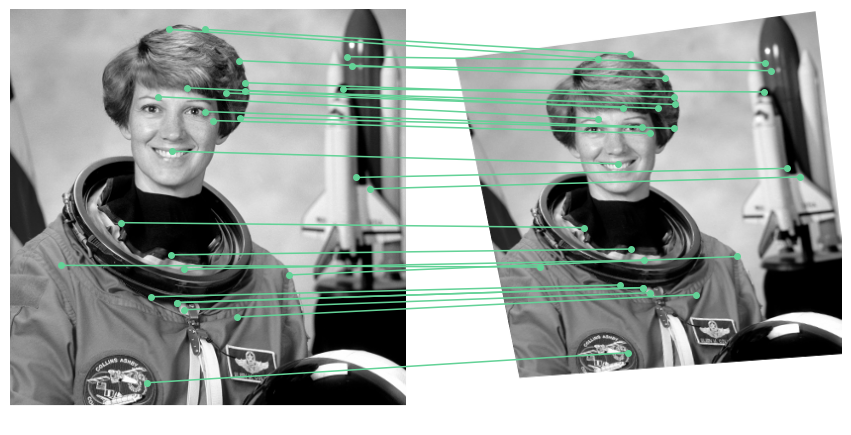

In [3]:
f = gris8(data.astronaut())[:400, 60:460]
H = np.array([[0.85, 0.18, 30], [-0.12, 0.88, 50], [-1.5e-4, 2e-4, 1.0]])
g = cv2.warpPerspective(f, H, (420, 420), borderValue=255)
s = cv2.SIFT_create(nfeatures=800)
ka, da = s.detectAndCompute(f, None)
kb, db = s.detectAndCompute(g, None)
pares = cv2.BFMatcher(cv2.NORM_L2).knnMatch(da, db, k=2)
buenos = []
for m, n in pares:
    if m.distance < 0.6 * n.distance:
        p = np.array([*ka[m.queryIdx].pt, 1.0])
        q = H @ p
        if np.hypot(*(q[:2] / q[2] - kb[m.trainIdx].pt)) < 3:
            buenos.append(m)
buenos = sorted(buenos, key=lambda m: m.distance)[:28]
lienzo = np.full((420, 400 + 20 + 420), 255, np.uint8)
lienzo[:400, :400] = f
lienzo[:420, 420:] = g
fig, ax = plt.subplots(figsize=(11, 5.4))
ax.imshow(lienzo, vmin=0, vmax=255)
for m in buenos:
    xa, ya = ka[m.queryIdx].pt
    xb, yb = kb[m.trainIdx].pt
    ax.plot([xa, xb + 420], [ya, yb], color=VERDE_CLARO, lw=1.1)
    ax.plot([xa, xb + 420], [ya, yb], "o", color=VERDE_CLARO, ms=4)
limpiar(ax)
plt.show()

¿Qué hace bueno a un punto? Recortemos un parche y busquemos en qué lugares de la imagen aparece.

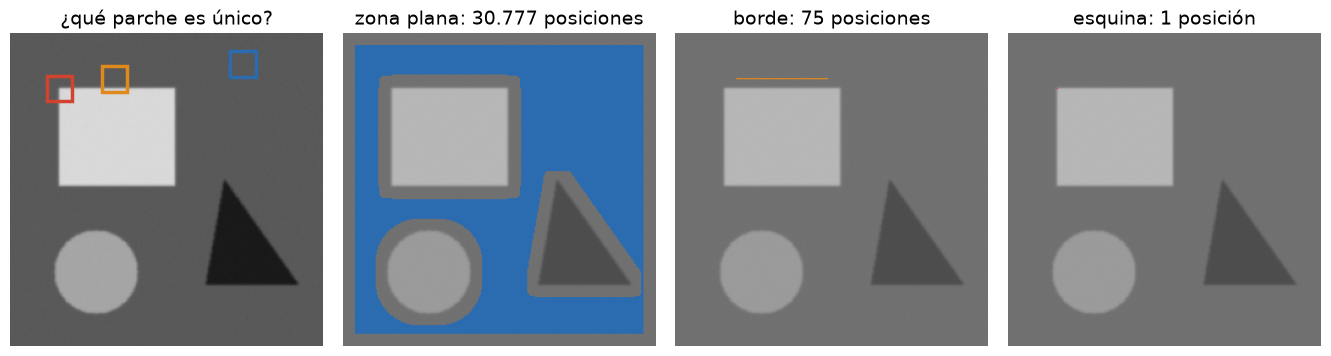

In [4]:
f = escena().astype(np.float32)
t = 21
casos = [("zona plana", (190, 25), AZUL), ("borde", (85, 37), NARANJA), ("esquina", (40, 45), ROJO)]
fig, ax = plt.subplots(1, 4, figsize=(13.5, 3.8))
ax[0].imshow(f, vmin=0, vmax=1)
ax[0].set_title("¿qué parche es único?")
for i, (nombre, (x, y), c) in enumerate(casos, 1):
    ax[0].add_patch(Rectangle((x - t / 2, y - t / 2), t, t, fill=False, color=c, lw=2.5))
    par = f[y - t // 2: y + t // 2 + 1, x - t // 2: x + t // 2 + 1]
    ssd = cv2.matchTemplate(f, par, cv2.TM_SQDIFF)
    m = np.ones(f.shape, bool)
    m[t // 2: t // 2 + ssd.shape[0], t // 2: t // 2 + ssd.shape[1]] = ssd > 0.25
    vista = np.dstack([f] * 3) * 0.55 + 0.25
    vista[~m] = matplotlib.colors.to_rgb(c)
    ax[i].imshow(vista)
    n = (~m).sum()
    ax[i].set_title(f"{nombre}: {n:,} {'posición' if n == 1 else 'posiciones'}".replace(",", "."))
limpiar(ax)
fig.tight_layout()
plt.show()

- **Zona plana:** aparece en casi todo el fondo. No sirve.
- **Borde:** aparece a lo largo de la línea. Sabemos la línea, pero no la posición sobre ella.
- **Esquina:** aparece en un solo lugar. Es lo que buscamos.

Un buen punto debe ser **repetible**, **distintivo**, **preciso** y **abundante**, y resistir cambios de rotación,
escala, iluminación y punto de vista.

---
## 2. Harris, programado a mano

### 2.1 La idea: mover una ventana

Un punto es bueno si, al mover una ventana pequeña en **cualquier dirección**, lo que se ve dentro cambia mucho.

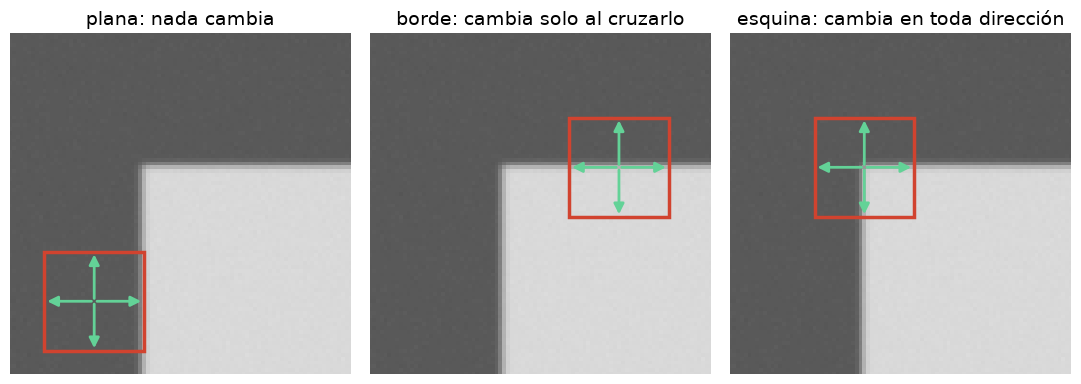

In [5]:
f = escena()[10:100, 5:95]
casos = [("plana: nada cambia", (22, 70)),
         ("borde: cambia solo al cruzarlo", (65, 35)),
         ("esquina: cambia en toda dirección", (35, 35))]
fig, ax = plt.subplots(1, 3, figsize=(11, 3.9))
for a, (t, (x, y)) in zip(ax, casos):
    a.imshow(f, vmin=0, vmax=1)
    L = 26
    a.add_patch(Rectangle((x - L / 2, y - L / 2), L, L, fill=False, color=ROJO, lw=2.5))
    for dx, dy in [(13, 0), (-13, 0), (0, 13), (0, -13)]:
        a.add_patch(FancyArrowPatch((x, y), (x + dx, y + dy), arrowstyle="-|>", mutation_scale=15,
                                    color=VERDE_CLARO, lw=2))
    a.set_title(t)
    a.set_xlim(0, 89)
    a.set_ylim(89, 0)
limpiar(ax)
fig.tight_layout()
plt.show()

### 2.2 Medir el cambio

Para un desplazamiento $(u, v)$:

$$E(u, v) = \sum_{x,y} w(x, y)\,\bigl[I(x + u, y + v) - I(x, y)\bigr]^2$$

donde $w(x, y)$ es la ventana. Calculemos $E$ directamente, probando muchos desplazamientos.

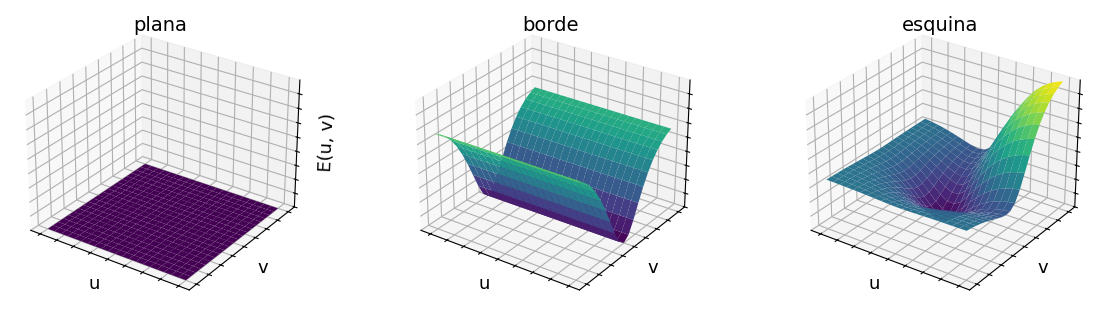

In [7]:
def superficie_E(f, x, y, r=12, m=10):
    yy, xx = np.mgrid[-r:r + 1, -r:r + 1]
    w = np.exp(-(xx**2 + yy**2) / (2 * (r / 2.5) ** 2))
    base = f[y - r: y + r + 1, x - r: x + r + 1]
    us = np.arange(-m, m + 1)
    E = np.zeros((len(us), len(us)))
    for i, v in enumerate(us):
        for j, u in enumerate(us):
            E[i, j] = (w * (f[y + v - r: y + v + r + 1, x + u - r: x + u + r + 1] - base) ** 2).sum()
    return us, E


f = escena()
casos = [("plana", (190, 35)), ("borde", (85, 45)), ("esquina", (40, 45))]
fig = plt.figure(figsize=(12, 3.9))
zmax = max(superficie_E(f, x, y)[1].max() for _, (x, y) in casos)
for k, (t, (x, y)) in enumerate(casos, 1):
    a = fig.add_subplot(1, 3, k, projection="3d")
    us, E = superficie_E(f, x, y)
    U, V = np.meshgrid(us, us)
    a.plot_surface(U, V, E, cmap="viridis", vmin=0, vmax=zmax, linewidth=0)
    a.set_zlim(0, zmax)
    a.set_title(t, y=0.98)
    a.set_xlabel("u", labelpad=-8)
    a.set_ylabel("v", labelpad=-8)
    if k == 1:
        a.set_zlabel("E(u, v)", labelpad=-8)
    a.tick_params(labelbottom=False, labelleft=False, labelsize=0, pad=-2)
    a.view_init(28, -55)
fig.subplots_adjust(left=0, right=0.96, wspace=0.05)
plt.show()

Plano: casi cero. Borde: un **valle** a lo largo del borde. Esquina: un **cuenco**.

### 2.3 Derivación

Probar todos los desplazamientos en cada píxel es demasiado caro. Harris lo aproxima con Taylor de primer orden:

$$I(x + u, y + v) \approx I(x, y) + I_x u + I_y v$$

Al reemplazar en $E$ se cancela $I(x, y)$:

$$E(u, v) \approx \sum w\,[I_x u + I_y v]^2 = \sum w\,[I_x^2 u^2 + 2 I_x I_y uv + I_y^2 v^2]$$

Como $u$ y $v$ no dependen de $(x, y)$, salen de la suma, y queda una **forma cuadrática**:

$$E(u, v) \approx \begin{bmatrix} u & v \end{bmatrix} M \begin{bmatrix} u \\ v \end{bmatrix},
\qquad M = \sum w \begin{bmatrix} I_x^2 & I_x I_y \\ I_x I_y & I_y^2 \end{bmatrix}$$

$M$ es la **matriz de estructura**. Se calcula una vez por píxel y sirve para todo $(u, v)$. Tiene productos de
derivadas **primeras**: no es la Hessiana.

Comprobemos que la aproximación funciona, comparando $E$ real con la forma cuadrática para desplazamientos pequeños.

In [8]:
f = escena()
x, y, r = 40, 45, 12                        # ventana sobre una esquina
yy, xx = np.mgrid[-r:r + 1, -r:r + 1]
w = np.exp(-(xx**2 + yy**2) / (2 * (r / 2.5) ** 2))
suave = ndimage.gaussian_filter(f, 1.0)
gy, gx = np.gradient(suave)
Ix, Iy = gx[y - r:y + r + 1, x - r:x + r + 1], gy[y - r:y + r + 1, x - r:x + r + 1]
M = np.array([[(w * Ix * Ix).sum(), (w * Ix * Iy).sum()],
              [(w * Ix * Iy).sum(), (w * Iy * Iy).sum()]])
print("M =\n", M.round(3))
print("\n (u, v)     E real     uᵀ M u")
base = suave[y - r:y + r + 1, x - r:x + r + 1]
for u, v in [(1, 0), (0, 1), (1, 1), (2, 0), (2, 2), (6, 6)]:
    mov = suave[y + v - r:y + v + r + 1, x + u - r:x + u + r + 1]
    E = (w * (mov - base) ** 2).sum()
    print(f"({u}, {v})   {E:9.4f}  {M[0, 0] * u**2 + 2 * M[0, 1] * u * v + M[1, 1] * v**2:9.4f}")

M =
 [[0.259 0.059]
 [0.059 0.262]]

 (u, v)     E real     uᵀ M u
(1, 0)      0.2713     0.2586
(0, 1)      0.2748     0.2617
(1, 1)      0.7075     0.6390
(2, 0)      0.9926     1.0343
(2, 2)      2.7329     2.5560
(6, 6)     14.8700    23.0036


Para desplazamientos pequeños coinciden bastante. Para $(6, 6)$ la aproximación ya se aleja: Taylor solo vale cerca de cero.

### 2.4 Lo que dicen los valores propios

En cada caso se muestran dos gráficos: la nube de gradientes de la ventana y la curva $E(u, v) = 1$. Esa curva es una
**elipse**, de semiejes $1/\sqrt{\lambda}$: un valor propio grande significa que $E$ sube rápido en esa dirección.

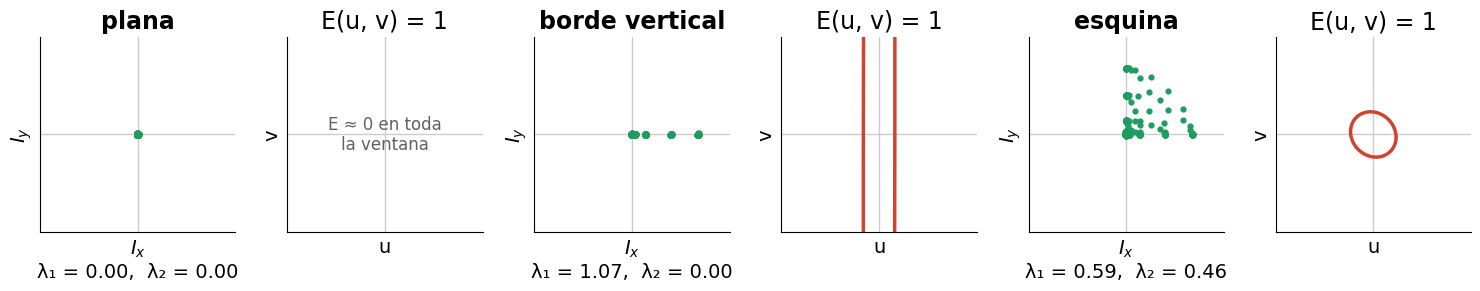

In [9]:
def M_de(f, x, y, r=10):
    Ix = ndimage.gaussian_filter(f, 1.0, order=(0, 1))[y - r: y + r + 1, x - r: x + r + 1]
    Iy = ndimage.gaussian_filter(f, 1.0, order=(1, 0))[y - r: y + r + 1, x - r: x + r + 1]
    M = np.array([[(Ix * Ix).sum(), (Ix * Iy).sum()], [(Ix * Iy).sum(), (Iy * Iy).sum()]])
    return Ix, Iy, M


f = escena()
casos = [("plana", (190, 35)), ("borde vertical", (40, 85)), ("esquina", (40, 45))]
fig, ax = plt.subplots(1, 6, figsize=(15, 3.4))
for j, (t, (x, y)) in enumerate(casos):
    Ix, Iy, M = M_de(f, x, y)
    lam, _ = np.linalg.eigh(M)
    a, b = ax[2 * j], ax[2 * j + 1]
    a.scatter(Ix.ravel(), Iy.ravel(), s=12, color=VERDE)
    a.axhline(0, color="0.8", lw=1, zorder=0)
    a.axvline(0, color="0.8", lw=1, zorder=0)
    a.set_xlim(-0.2, 0.2)
    a.set_ylim(-0.2, 0.2)
    a.set_aspect("equal")
    a.set_xticks([])
    a.set_yticks([])
    a.set_title(t, fontsize=17, fontweight="bold")
    a.set_xlabel(f"$I_x$\nλ₁ = {lam[1]:.2f},  λ₂ = {lam[0]:.2f}", fontsize=14)
    a.set_ylabel("$I_y$", fontsize=14)
    us = np.linspace(-6, 6, 300)
    U, V = np.meshgrid(us, us)
    E = M[0, 0] * U**2 + 2 * M[0, 1] * U * V + M[1, 1] * V**2
    b.contour(U, V, E, levels=[1.0], colors=[ROJO], linewidths=2.5)
    if lam[1] < 1e-3:
        b.text(0, 0, "E ≈ 0 en toda\nla ventana", ha="center", va="center", color=GRIS, fontsize=12)
    b.axhline(0, color="0.8", lw=1, zorder=0)
    b.axvline(0, color="0.8", lw=1, zorder=0)
    b.set_aspect("equal")
    b.set_xticks([])
    b.set_yticks([])
    b.set_title("E(u, v) = 1", fontsize=17)
    b.set_xlabel("u\n ", fontsize=14)
    b.set_ylabel("v", fontsize=14)
fig.tight_layout(w_pad=1.2)
plt.show()

| $\lambda_1$ y $\lambda_2$ | Zona | Comportamiento de $E$ |
|---|---|---|
| ambos pequeños | plana | casi no cambia |
| uno grande, otro pequeño | borde | cambia solo en una dirección |
| ambos grandes | esquina | cambia en toda dirección |

### 2.5 La respuesta de Harris

Para no calcular valores propios en cada píxel, se usa que $\det M = \lambda_1\lambda_2$ y $\operatorname{tr} M = \lambda_1 + \lambda_2$:

$$R = \det M - k\,(\operatorname{tr} M)^2,\qquad k \in [0.04,\ 0.06]$$

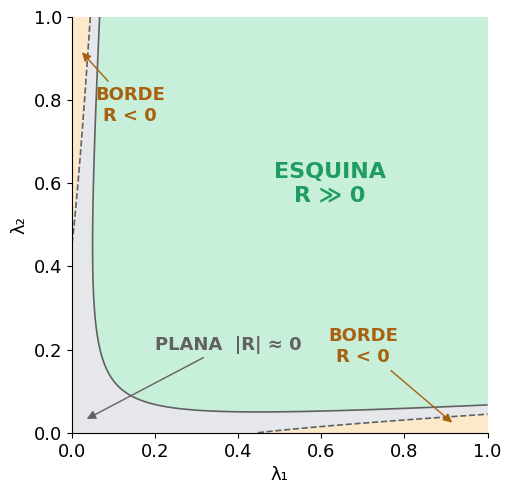

In [10]:
k, lim = 0.05, 1.0
l1, l2 = np.meshgrid(np.linspace(0, lim, 500), np.linspace(0, lim, 500))
R = l1 * l2 - k * (l1 + l2) ** 2
umbral = 0.01
zonas = np.where(R > umbral, 2, np.where(R < -umbral, 0, 1))
fig, ax = plt.subplots(figsize=(6.2, 5.4))
ax.contourf(l1, l2, zonas, levels=[-0.5, 0.5, 1.5, 2.5], colors=["#fde9c9", "#e5e7eb", "#c7efd9"])
ax.contour(l1, l2, R, levels=[-umbral, umbral], colors=[GRIS], linewidths=1.2)
ax.text(0.62, 0.60, "ESQUINA\nR ≫ 0", ha="center", va="center", color=VERDE, fontweight="bold", fontsize=16)
for xy, txt in [((0.92, 0.02), (0.70, 0.17)), ((0.02, 0.92), (0.14, 0.75))]:
    ax.annotate("BORDE\nR < 0", xy, txt, color="#a8620f", fontweight="bold", ha="center",
                arrowprops=dict(arrowstyle="-|>", color="#a8620f"))
ax.annotate("PLANA  |R| ≈ 0", (0.03, 0.03), (0.2, 0.2), color=GRIS, fontweight="bold",
            arrowprops=dict(arrowstyle="-|>", color=GRIS))
ax.set_xlabel("λ₁")
ax.set_ylabel("λ₂")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_aspect("equal")
plt.show()

### 2.6 El algoritmo

1. Gradientes $I_x$, $I_y$.
2. Productos $I_x^2$, $I_y^2$, $I_x I_y$, píxel a píxel.
3. Filtrar cada producto con una gaussiana $w$: da $M$ en cada píxel.
4. Calcular $R$.
5. Umbral y supresión de no máximos.

Son pocas líneas con lo que ya vimos en filtrado:

In [11]:
def harris(f, sigma_d=1.0, sigma_i=2.0, k=0.05):
    # Devuelve R y los pasos intermedios
    Ix = ndimage.gaussian_filter(f, sigma_d, order=(0, 1))
    Iy = ndimage.gaussian_filter(f, sigma_d, order=(1, 0))
    Sxx = ndimage.gaussian_filter(Ix * Ix, sigma_i)
    Syy = ndimage.gaussian_filter(Iy * Iy, sigma_i)
    Sxy = ndimage.gaussian_filter(Ix * Iy, sigma_i)
    R = Sxx * Syy - Sxy**2 - k * (Sxx + Syy) ** 2
    return R, dict(Ix=Ix, Iy=Iy, Sxx=Sxx, Syy=Syy, Sxy=Sxy)


def maximos(R, umbral, radio=5):
    es_max = R == ndimage.maximum_filter(R, size=2 * radio + 1)
    y, x = np.nonzero(es_max & (R > umbral))
    return x, y

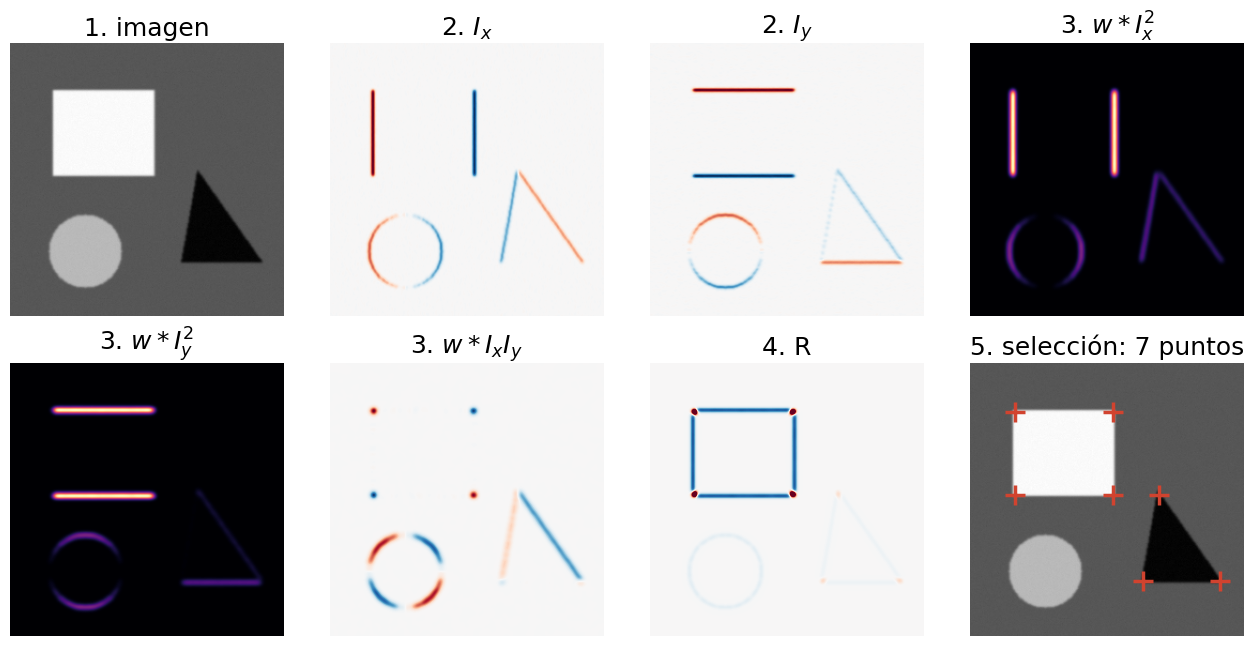

In [12]:
f = escena()
R, p = harris(f)
x, y = maximos(R, 0.02 * R.max())
fig, ax = plt.subplots(2, 4, figsize=(13, 6.6))
vistas = [(f, "1. imagen", "gray", None), (p["Ix"], "2. $I_x$", "RdBu_r", "sim"), (p["Iy"], "2. $I_y$", "RdBu_r", "sim"),
          (p["Sxx"], "3. $w * I_x^2$", "magma", None), (p["Syy"], "3. $w * I_y^2$", "magma", None),
          (p["Sxy"], "3. $w * I_xI_y$", "RdBu_r", "sim"), (R, "4. R", "RdBu_r", "sim"), (f, f"5. selección: {len(x)} puntos", "gray", None)]
for a, (im, t, cm, modo) in zip(ax.ravel(), vistas):
    kw = {}
    if modo == "sim":
        m = np.abs(im).max() * (0.35 if t == "4. R" else 1)
        kw = dict(vmin=-m, vmax=m)
    a.imshow(im, cmap=cm, **kw)
    a.set_title(t, fontsize=18)
ax[1, 3].plot(x, y, "+", color=ROJO, ms=14, mew=2.5)
limpiar(ax)
fig.tight_layout()
plt.show()

Así se compara con OpenCV. `cv2.cornerHarris` usa Sobel y una ventana de caja, por lo que los valores de $R$ no son
iguales, pero las esquinas deben coincidir.

A mano: 7 puntos   OpenCV: 7 puntos
Distancia de cada punto al más cercano de OpenCV: [0. 0. 0. 0. 1. 0. 0.]


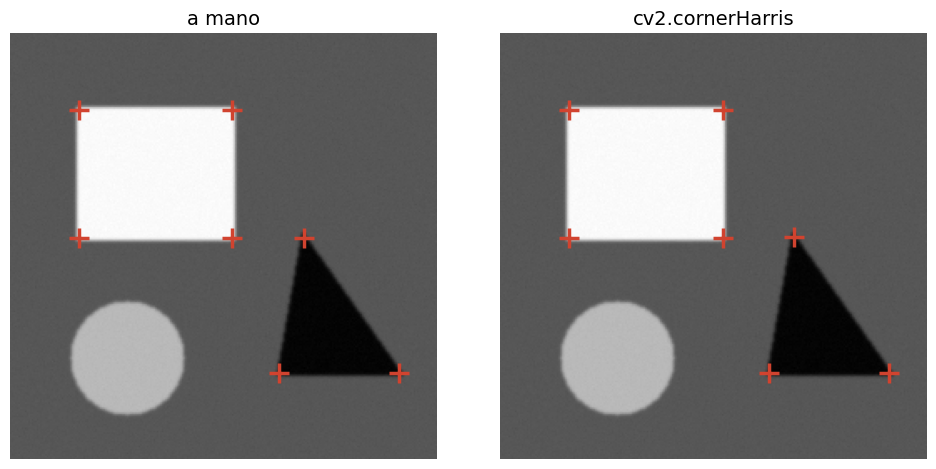

In [13]:
f = escena()
R_mano, _ = harris(f)
x_m, y_m = maximos(R_mano, 0.02 * R_mano.max())
R_cv = cv2.cornerHarris(np.float32(f), blockSize=5, ksize=3, k=0.05)
x_c, y_c = maximos(R_cv, 0.02 * R_cv.max())
print(f"A mano: {len(x_m)} puntos   OpenCV: {len(x_c)} puntos")
dist = [np.hypot(x_c - a, y_c - b).min() for a, b in zip(x_m, y_m)]
print("Distancia de cada punto al más cercano de OpenCV:", np.round(dist, 1))

fig, ax = plt.subplots(1, 2, figsize=(10, 4.8))
ax[0].imshow(f)
ax[0].plot(x_m, y_m, "+", color=ROJO, ms=14, mew=2.5)
ax[0].set_title("a mano")
ax[1].imshow(f)
ax[1].plot(x_c, y_c, "+", color=ROJO, ms=14, mew=2.5)
ax[1].set_title("cv2.cornerHarris")
limpiar(ax)
fig.tight_layout()
plt.show()

### 2.7 Efecto de los parámetros

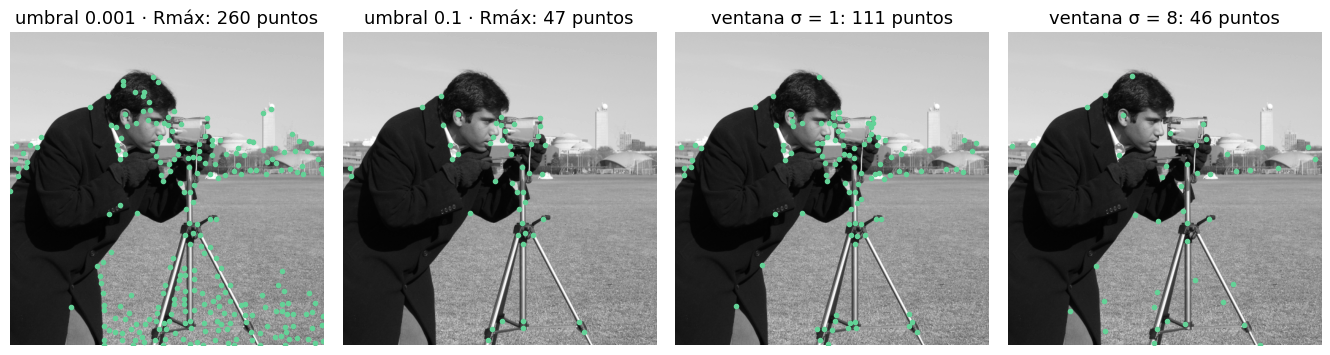

In [53]:
f = gris(data.camera())
fig, ax = plt.subplots(1, 4, figsize=(13.5, 3.8))
R0, _ = harris(f)
for a, u in zip(ax[:2], [0.001, 0.1]):
    x, y = maximos(R0, u * R0.max())
    a.imshow(f)
    a.plot(x, y, ".", color=VERDE_CLARO, ms=6)
    a.set_title(f"umbral {u:g} · Rmáx: {len(x)} puntos", fontsize=13)
for a, s in zip(ax[2:], [1, 8]):
    R, _ = harris(f, sigma_i=s)
    x, y = maximos(R, 0.01 * R.max())
    a.imshow(f)
    a.plot(x, y, ".", color=VERDE_CLARO, ms=6)
    a.set_title(f"ventana σ = {s}: {len(x)} puntos", fontsize=13)
limpiar(ax)
fig.tight_layout()
plt.show()

### 2.8 Explora Harris

Cambia la imagen, $k$, el umbral y el tamaño de la ventana. ¿Qué parámetro cambia más el resultado?

In [15]:
@interact(imagen=widgets.Dropdown(options=opciones_imagenes(), value="camera"),
          sigma_i=widgets.FloatSlider(value=2, min=0.5, max=10, step=0.5, description="σ ventana", continuous_update=False),
          k=widgets.FloatSlider(value=0.05, min=0.02, max=0.2, step=0.01, continuous_update=False),
          umbral=widgets.FloatLogSlider(value=0.01, base=10, min=-4, max=-0.5, step=0.25, continuous_update=False))
def explorar_harris(imagen, sigma_i, k, umbral):
    f = cargar(imagen).astype(float) / 255
    R, _ = harris(f, sigma_i=sigma_i, k=k)
    x, y = maximos(R, umbral * R.max())
    m = np.percentile(np.abs(R), 99.5) + 1e-12
    fig, ax = plt.subplots(1, 2, figsize=(11, 5))
    ax[0].imshow(R, cmap="RdBu_r", vmin=-m, vmax=m)
    ax[0].set_title("R")
    ax[1].imshow(f)
    ax[1].plot(x, y, ".", color=VERDE_CLARO, ms=6)
    ax[1].set_title(f"{len(x)} puntos")
    limpiar(ax)
    fig.tight_layout()
    plt.show()

interactive(children=(Dropdown(description='imagen', index=1, options=('astronaut', 'camera', 'coffee', 'chels…

### 2.9 ¿Qué resiste Harris?

**Rotación:** $M$ se transforma como $Q M Q^T$, así que los valores propios y $R$ no cambian.

**Iluminación:** sumar una constante no cambia los gradientes. Multiplicar por $c$ multiplica los gradientes por $c$,
$M$ por $c^2$ y $R$ por $c^4$. Comprobémoslo:

In [16]:
f = gris(data.camera())
R, _ = harris(f)
x, y = maximos(R, 0.05 * R.max())
i = np.argmax(R[y, x])                   # la esquina más fuerte
xs, ys = x[i], y[i]

R_suma, _ = harris(f + 0.1)
print(f"I + 0.1:   R cambia por un factor {R_suma[ys, xs] / R[ys, xs]:.4f}   (esperado: 1)")
for c in (0.5, 2, 3):
    R_c, _ = harris(c * f)
    print(f"{c} · I:   R cambia por un factor {R_c[ys, xs] / R[ys, xs]:8.4f}   (esperado: c⁴ = {c**4})")

# Rotación de 90°: los mismos valores, en otra posición
R_rot, _ = harris(np.rot90(f))
print(f"\nRotación de 90°: Rmáx pasa de {R.max():.4e} a {R_rot.max():.4e}")

I + 0.1:   R cambia por un factor 1.0000   (esperado: 1)
0.5 · I:   R cambia por un factor   0.0625   (esperado: c⁴ = 0.0625)
2 · I:   R cambia por un factor  16.0000   (esperado: c⁴ = 16)
3 · I:   R cambia por un factor  81.0000   (esperado: c⁴ = 81)

Rotación de 90°: Rmáx pasa de 1.8762e-04 a 1.8762e-04


**Escala:** aquí Harris falla, porque la ventana tiene un tamaño fijo. La misma esquina redondeada, con el mismo
detector y el mismo umbral. **La ventana verde tiene igual tamaño en píxeles en ambas imágenes.**

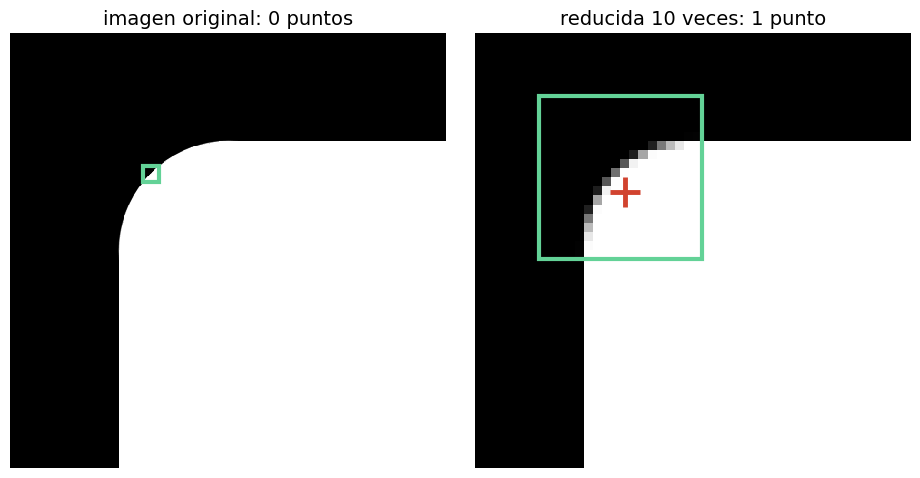

In [17]:
g = np.zeros((480, 480), np.uint8)
cv2.rectangle(g, (120, 120), (480, 480), 255, -1)
g[120:240, 120:240] = 0
cv2.circle(g, (240, 240), 120, 255, -1, cv2.LINE_AA)
fac = 10
chico = cv2.resize(g, (480 // fac, 480 // fac), interpolation=cv2.INTER_AREA)
s_i = 3
margen = 8

def R_sin_marco(im, m):
    R, _ = harris(im.astype(float) / 255, 1, s_i)
    fuera = np.ones_like(R, bool)
    fuera[m:-m, m:-m] = False
    R[fuera] = -1
    return R
Rg, Rc = R_sin_marco(g, margen), R_sin_marco(chico, margen)
umbral = 0.1 * Rc.max()
fig, ax = plt.subplots(1, 2, figsize=(9.5, 4.8))
datos = [(g, Rg, "imagen original", 240), (chico, Rc, f"reducida {fac} veces", 24)]
for a, (im, R, t, _) in zip(ax, datos):
    x, y = maximos(R, umbral, radio=3)
    a.imshow(im, vmin=0, vmax=255, interpolation="nearest")
    a.plot(x, y, "+", color=ROJO, ms=22, mew=3.5)
    a.set_title(f"{t}: {len(x)} {'punto' if len(x) == 1 else 'puntos'}")
    # ventana de la misma cantidad de píxeles en las dos imágenes
    L = 6 * s_i
    cx, cy = (155, 155) if im.shape[0] > 100 else (15.5, 15.5)
    a.add_patch(Rectangle((cx - L / 2, cy - L / 2), L, L, fill=False, color=VERDE_CLARO, lw=3))
limpiar(ax)
fig.tight_layout()
plt.show()

En la imagen original, la ventana solo ve un trozo de arco que parece recto, y $R$ es negativa: un borde. Reducida,
la misma ventana ve toda la curva: una esquina. La pregunta no es solo dónde, sino también **a qué escala** mirar.

---
## 3. El problema de la escala: de LoG a DoG

### 3.1 Cada estructura tiene su escala

La respuesta del LoG **normalizado**, $\sigma^2 \nabla^2 G$, tiene un máximo en una escala que crece con el objeto.
Para un disco de radio $r$, ese máximo está en $\sigma^* = r/\sqrt{2}$.

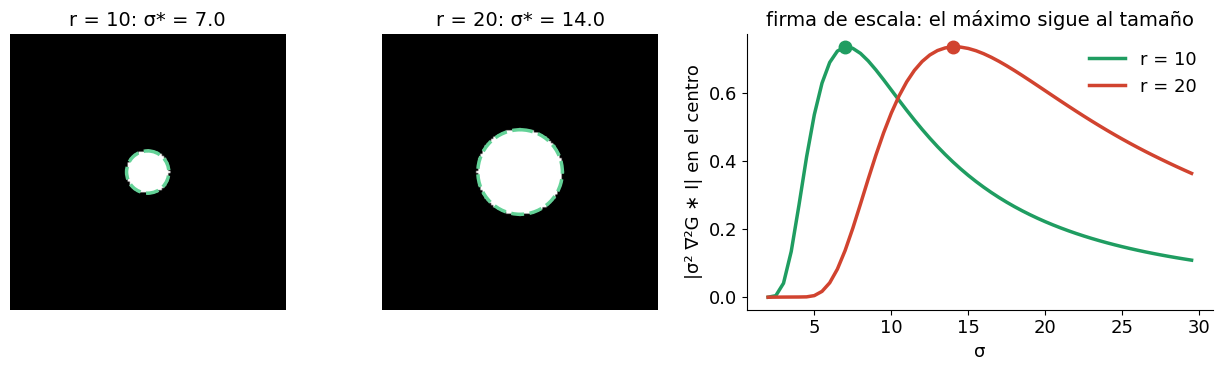

In [18]:
radios = [10, 20]
sigmas = np.arange(2, 30, 0.5)
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.9), gridspec_kw=dict(width_ratios=[1, 1, 1.6]))
for a, r, c in zip(ax[:2], radios, [VERDE, ROJO]):
    im = np.zeros((129, 129))
    cv2.circle(im, (64, 64), r, 1.0, -1, cv2.LINE_AA)
    a.imshow(im, vmin=0, vmax=1)
    rta = [-(s**2) * ndimage.gaussian_laplace(im, s)[64, 64] for s in sigmas]
    sm = sigmas[int(np.argmax(rta))]
    a.add_patch(Circle((64, 64), sm * np.sqrt(2), fill=False, color=VERDE_CLARO, lw=2.5, ls="--"))
    a.set_title(f"r = {r}: σ* = {sm:.1f}")
    limpiar(a)
    ax[2].plot(sigmas, rta, color=c, lw=2.5, label=f"r = {r}")
    ax[2].plot(sm, max(rta), "o", color=c, ms=9)
ax[2].set_xlabel("σ")
ax[2].set_ylabel("|σ² ∇²G ∗ I| en el centro")
ax[2].legend(frameon=False)
ax[2].set_title("firma de escala: el máximo sigue al tamaño")
fig.tight_layout()
plt.show()

### 3.2 De LoG a DoG

El LoG es caro. Lowe usa la diferencia de gaussianas. De la ecuación del calor:

$$\frac{\partial G}{\partial \sigma} = \sigma \nabla^2 G
\qquad\Rightarrow\qquad
\frac{G(k\sigma) - G(\sigma)}{k\sigma - \sigma} \approx \sigma \nabla^2 G
\qquad\Rightarrow\qquad
G(k\sigma) - G(\sigma) \approx (k - 1)\,\sigma^2 \nabla^2 G$$

La DoG **ya viene normalizada** y solo requiere restar imágenes. Comparemos ambas:

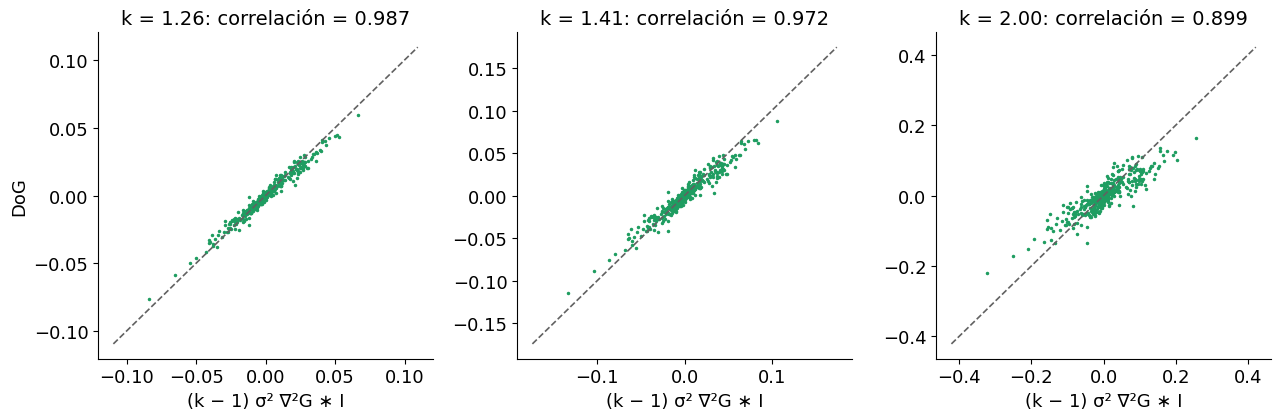

In [19]:
f = gris(data.camera())
sigma = 4.0
fig, ax = plt.subplots(1, 3, figsize=(13, 4.4))
for a, k in zip(ax, (2 ** (1 / 3), 2 ** (1 / 2), 2.0)):
    dog = ndimage.gaussian_filter(f, k * sigma) - ndimage.gaussian_filter(f, sigma)
    log = (k - 1) * sigma**2 * ndimage.gaussian_laplace(f, sigma)
    corr = np.corrcoef(dog.ravel(), log.ravel())[0, 1]
    a.plot(log[::16, ::16].ravel(), dog[::16, ::16].ravel(), ".", color=VERDE, ms=3)
    lim = np.abs(log).max()
    a.plot([-lim, lim], [-lim, lim], "--", color=GRIS, lw=1.2)
    a.set_xlabel("(k − 1) σ² ∇²G ∗ I")
    a.set_title(f"k = {k:.2f}: correlación = {corr:.3f}")
ax[0].set_ylabel("DoG")
fig.tight_layout()
plt.show()

### 3.3 El espacio de escalas

Dentro de una **octava**, $\sigma$ crece por un factor $k$. Al pasar a la siguiente, la imagen se reduce a la mitad.
Aquí se usa $k = \sqrt{2}$ por claridad; SIFT usa por defecto $k = 2^{1/3}$ y $\sigma_0 = 1.6$.

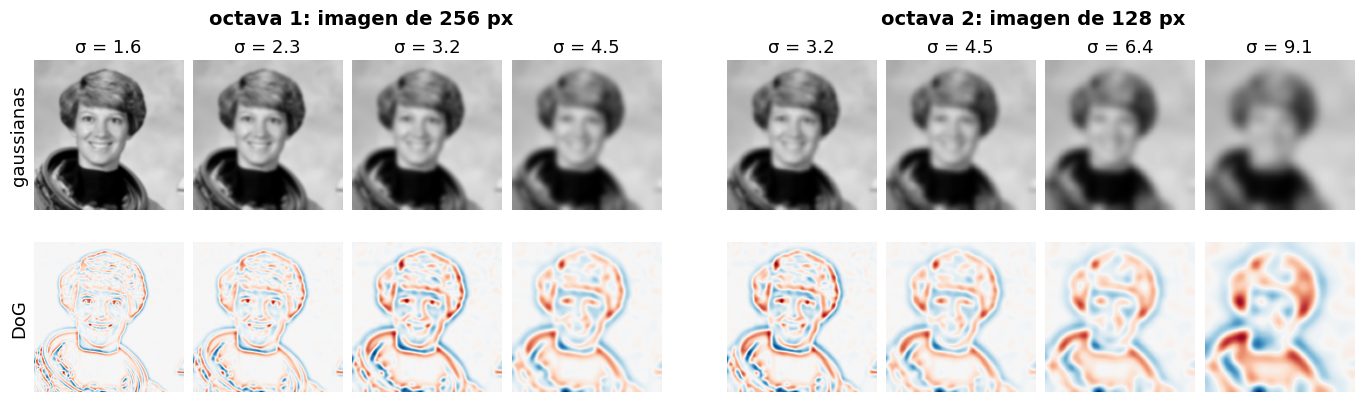

In [20]:
f = gris(data.astronaut())[0:256, 110:366]
s0, k = 1.6, 2 ** (1 / 2)
fig = plt.figure(figsize=(14, 4.0))
externa = fig.add_gridspec(1, 2, wspace=0.1, left=0.05, right=0.995, top=0.86, bottom=0.03)
for o in range(2):
    interna = externa[o].subgridspec(2, 4, wspace=0.05, hspace=0.22)
    base = cv2.resize(f, None, fx=0.5**o, fy=0.5**o, interpolation=cv2.INTER_AREA)
    L = [ndimage.gaussian_filter(base, s0 * k**i) for i in range(5)]
    for i in range(4):
        a = fig.add_subplot(interna[0, i])
        a.imshow(L[i], vmin=0, vmax=1)
        a.set_title(f"σ = {s0 * k**i * 2**o:.1f}", fontsize=13)
        b = fig.add_subplot(interna[1, i])
        d = L[i + 1] - L[i]
        m = np.abs(d).max()
        b.imshow(d, cmap="RdBu_r", vmin=-m, vmax=m)
        limpiar([a, b])
        if i == 0 and o == 0:
            a.set_ylabel("gaussianas", fontsize=13)
            b.set_ylabel("DoG", fontsize=13)
    fig.text(0.05 + 0.48 * o + 0.235, 0.95, f"octava {o + 1}: imagen de {base.shape[0]} px", ha="center", fontsize=14, fontweight="bold")
plt.show()

### 3.4 Buscar extremos en 3D

Un píxel es candidato si es mayor o menor que sus **26 vecinos**: 8 en su nivel, 9 arriba y 9 abajo.

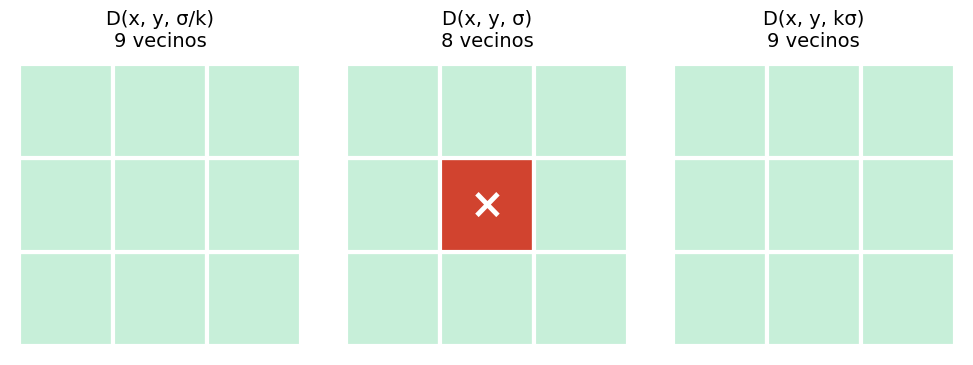

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(10, 3.6))
nombres = ["D(x, y, σ/k)\n9 vecinos", "D(x, y, σ)\n8 vecinos", "D(x, y, kσ)\n9 vecinos"]
for a, n, j in zip(ax, nombres, range(3)):
    for x in range(3):
        for y in range(3):
            centro = j == 1 and x == 1 and y == 1
            a.add_patch(Rectangle((x, y), 1, 1, fc=ROJO if centro else "#c7efd9", ec="white", lw=3))
            if centro:
                a.text(x + 0.5, y + 0.5, "×", color="white", ha="center", va="center", fontsize=30, fontweight="bold")
    a.set_xlim(-0.1, 3.1)
    a.set_ylim(-0.1, 3.1)
    a.set_aspect("equal")
    a.set_title(n)
limpiar(ax)
fig.tight_layout()
plt.show()

Programemos esta búsqueda en una imagen con discos de varios tamaños. Si la idea funciona, cada disco debe dar un
extremo, con una escala proporcional a su radio. El signo de la DoG separa las manchas claras de las oscuras.

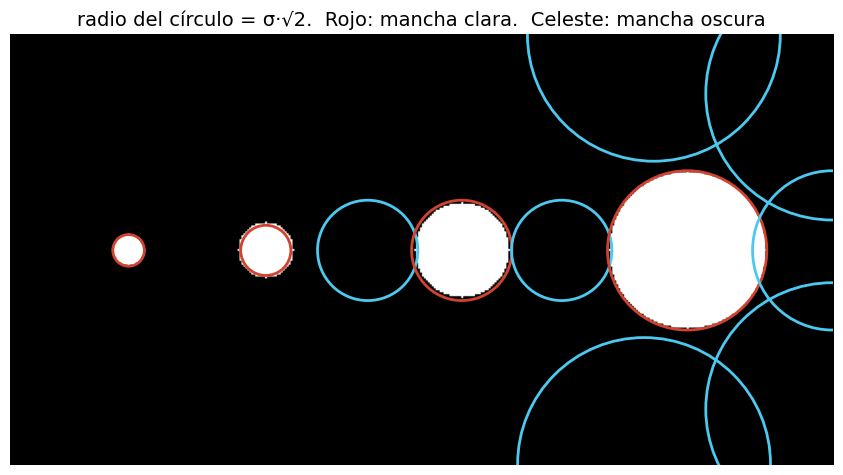

disco r =  8: σ encontrado = [5.7]   r/√2 = 5.7
disco r = 14: σ encontrado = [9.1]   r/√2 = 9.9
disco r = 24: σ encontrado = [18.1]   r/√2 = 17.0
disco r = 40: σ encontrado = [28.7]   r/√2 = 28.3


In [22]:
def extremos_dog(f, sigma0=1.6, k=2 ** (1 / 3), niveles=16, umbral=0.03):
    # Pila de DoG: D[nivel, fila, columna]
    sigmas = sigma0 * k ** np.arange(niveles + 1)
    L = np.stack([ndimage.gaussian_filter(f, s) for s in sigmas])
    D = L[1:] - L[:-1]
    # Un extremo es el máximo o el mínimo de su cubo de 3 x 3 x 3
    es_max = D == ndimage.maximum_filter(D, size=3)
    es_min = D == ndimage.minimum_filter(D, size=3)
    candidatos = (es_max | es_min) & (np.abs(D) > umbral)
    candidatos[[0, -1]] = False          # los niveles extremos no tienen vecinos arriba o abajo
    n, y, x = np.nonzero(candidatos)
    # Cada nivel de DoG está entre σ y kσ: su escala es la media geométrica
    return x, y, sigmas[n] * np.sqrt(k), D[n, y, x] < 0     # en una mancha clara, la DoG es negativa


discos = np.zeros((220, 420))
radios = [(60, 110, 8), (130, 110, 14), (230, 110, 24), (345, 110, 40)]
for cx, cy, r in radios:
    cv2.circle(discos, (cx, cy), r, 1.0, -1, cv2.LINE_AA)

x, y, s, clara = extremos_dog(discos)
fig, ax = plt.subplots(figsize=(11, 5.6))
ax.imshow(discos, vmin=0, vmax=1)
for a, b, c, es_clara in zip(x, y, s, clara):
    ax.add_patch(Circle((a, b), c * np.sqrt(2), fill=False, color=ROJO if es_clara else "#4cc9f0", lw=2))
ax.set_title("radio del círculo = σ·√2.  Rojo: mancha clara.  Celeste: mancha oscura")
limpiar(ax)
plt.show()

for cx, cy, r in radios:
    cerca = clara & (np.hypot(x - cx, y - cy) < 3)
    print(f"disco r = {r:2d}: σ encontrado = {np.round(s[cerca], 1)}   r/√2 = {r / np.sqrt(2):.1f}")

Cada disco da un extremo, y su $\sigma$ queda cerca de $r/\sqrt{2}$, dentro de la resolución de los niveles. Los círculos
celestes también son correctos: el espacio negro entre discos es una **mancha oscura**. Por eso SIFT encuentra puntos de ambos
tipos. En una imagen real, los filtros de la sección siguiente eliminan los que son débiles o inestables.

---
## 4. SIFT

Cuatro etapas (Lowe, 2004):

1. **Extremos en DoG:** posición y escala.
2. **Depurar:** quitar los puntos de bajo contraste y los que están sobre bordes.
3. **Orientación:** invariancia a rotación.
4. **Descriptor:** 4 × 4 histogramas de 8 ángulos.

La idea central es **normalizar**: se mide en un parche ajustado a la escala y a la orientación del punto.

### 4.1 Quitar lo inestable

En OpenCV se puede ver el efecto de cada filtro, desactivándolos con sus parámetros.

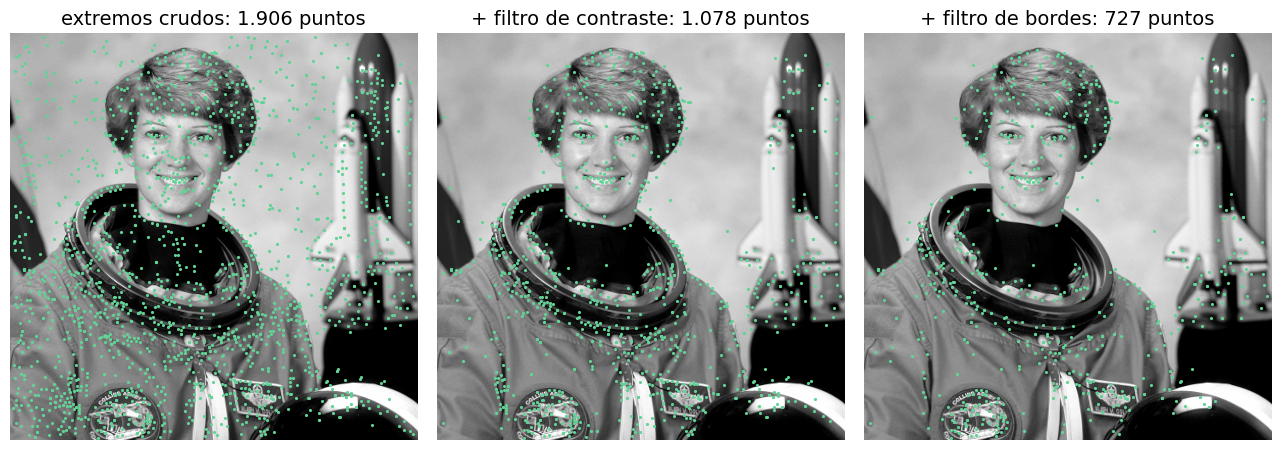

In [23]:
f = gris8(data.astronaut())[:400, 60:460]
conf = [("extremos crudos", dict(contrastThreshold=1e-5, edgeThreshold=1e6)),
        ("+ filtro de contraste", dict(contrastThreshold=0.04, edgeThreshold=1e6)),
        ("+ filtro de bordes", dict(contrastThreshold=0.04, edgeThreshold=10))]
fig, ax = plt.subplots(1, 3, figsize=(13, 4.6))
for a, (t, kw) in zip(ax, conf):
    kps = cv2.SIFT_create(**kw).detect(f, None)
    a.imshow(f)
    a.plot([k.pt[0] for k in kps], [k.pt[1] for k in kps], ".", color=VERDE_CLARO, ms=2.5)
    a.set_title(f"{t}: {len(kps):,} puntos".replace(",", "."))
limpiar(ax)
fig.tight_layout()
plt.show()

El filtro de bordes usa la Hessiana $H$ de la DoG, y exige que $(\operatorname{tr} H)^2 / \det H < (r + 1)^2 / r$, con
$r = 10$. Es la misma estrategia de Harris: traza y determinante, sin calcular valores propios.

### 4.2 Asignar una orientación

Histograma de **36 bins** de los gradientes alrededor del punto, pesados por magnitud y por una gaussiana.
El **peak** da la orientación. Los bins que superan 80 % del peak generan puntos adicionales.

Al rotar la imagen, el peak se traslada. Como $y$ crece hacia abajo, una rotación antihoraria **resta** ese ángulo.

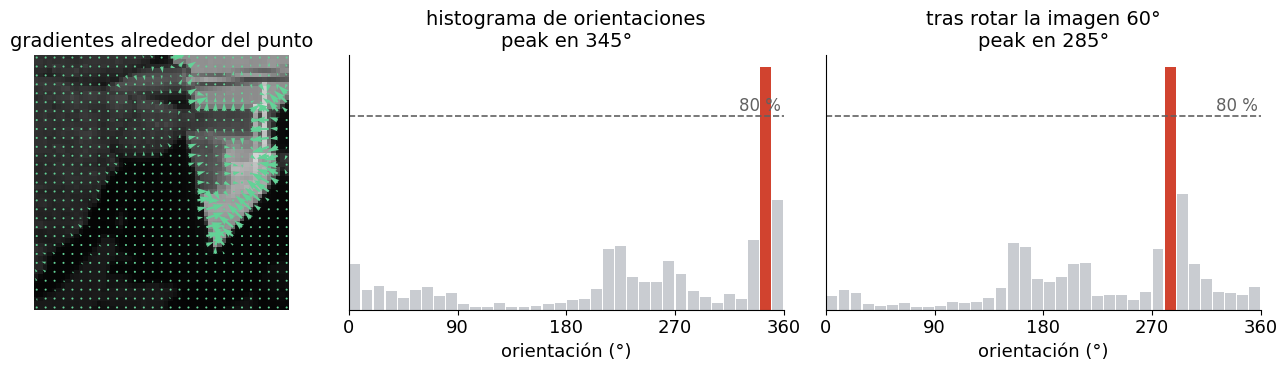

In [24]:
def histo_orientacion(f, x, y, sigma):
    r = int(round(4.5 * sigma))
    gy, gx = np.gradient(ndimage.gaussian_filter(f, 1.0))
    yy, xx = np.mgrid[y - r: y + r + 1, x - r: x + r + 1]
    w = np.exp(-((xx - x) ** 2 + (yy - y) ** 2) / (2 * (1.5 * sigma) ** 2))
    gx, gy = gx[yy, xx], gy[yy, xx]
    mag = np.hypot(gx, gy) * w
    ang = np.rad2deg(np.arctan2(gy, gx)) % 360
    h, _ = np.histogram(ang, bins=36, range=(0, 360), weights=mag)
    return h, gx, gy, xx, yy


f = gris(data.camera())
x, y, sigma = 236, 231, 6.2
h1, gx, gy, xx, yy = histo_orientacion(f, x, y, sigma)
giro = 60
M = cv2.getRotationMatrix2D((256.0, 256.0), giro, 1.0)
g = cv2.warpAffine(f, M, (512, 512), flags=cv2.INTER_CUBIC)
xr, yr = M @ np.array([x, y, 1.0])
h2, *_ = histo_orientacion(g, int(round(xr)), int(round(yr)), sigma)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.9), gridspec_kw=dict(width_ratios=[1, 1.5, 1.5]))
r = xx.shape[0] // 2
ax[0].imshow(f[y - r: y + r + 1, x - r: x + r + 1], vmin=0, vmax=1)
paso = 2
ax[0].quiver(np.arange(0, 2 * r + 1, paso), np.arange(0, 2 * r + 1, paso), gx[::paso, ::paso], gy[::paso, ::paso],
             color=VERDE_CLARO, angles="xy", scale_units="xy", scale=np.hypot(gx, gy).max() / 5, width=0.009)
ax[0].set_title("gradientes alrededor del punto")
limpiar(ax[0])
bins = np.arange(36) * 10 + 5
for a, h, t in zip(ax[1:], [h1, h2], ["histograma de orientaciones", f"tras rotar la imagen {giro}°"]):
    peak = h.max()
    cols = [ROJO if v == peak else (NARANJA if v >= 0.8 * peak else "#c9ccd1") for v in h]
    a.bar(bins, h, width=9, color=cols)
    a.axhline(0.8 * peak, color=GRIS, ls="--", lw=1.2)
    a.text(358, 0.82 * peak, "80 %", color=GRIS, ha="right", fontsize=12)
    a.set_xlim(0, 360)
    a.set_xticks(range(0, 361, 90))
    a.set_xlabel("orientación (°)")
    a.set_yticks([])
    a.set_title(f"{t}\npeak en {bins[np.argmax(h)]}°")
fig.tight_layout()
plt.show()

### 4.3 El descriptor de 128 valores

Es un punto real y su descriptor real de OpenCV. El parche se gira según la orientación y se ajusta a la escala; luego se
divide en 4 × 4 celdas con un histograma de 8 ángulos cada una: $4 \times 4 \times 8 = 128$.

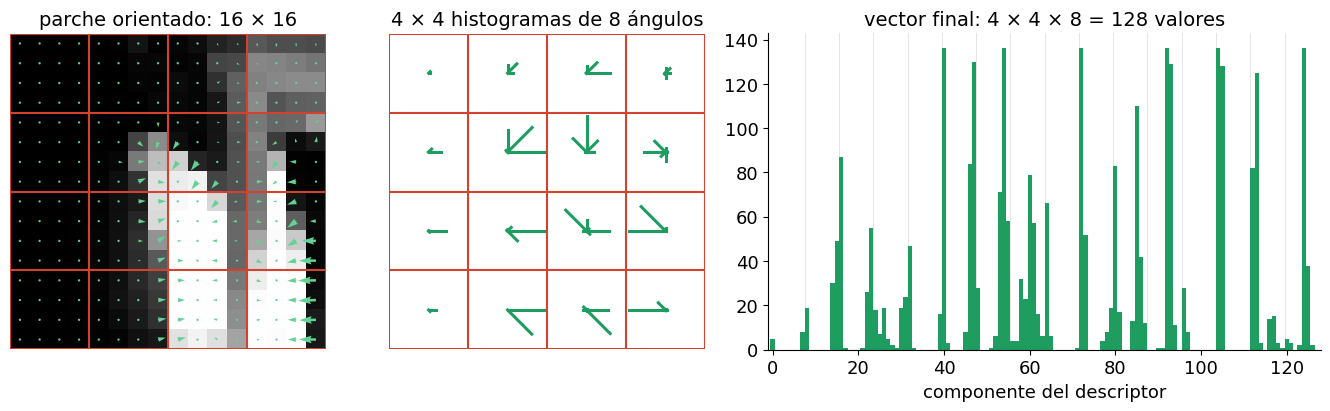

In [25]:
f8 = gris8(data.astronaut())
s = cv2.SIFT_create()
kps, des = s.detectAndCompute(f8, None)
cand = [i for i, k in enumerate(kps) if 3.5 < k.size / 2 < 6 and 60 < k.pt[0] < 450 and 60 < k.pt[1] < 450]
i = max(cand, key=lambda j: kps[j].response)
kp, d = kps[i], des[i]
lado = 16
celda = 3 * kp.size / 2 * 1.0
escala = (4 * celda) / lado
M = cv2.getRotationMatrix2D(kp.pt, kp.angle, 1 / escala)
M[:, 2] += np.array([lado / 2, lado / 2]) - kp.pt
parche = cv2.warpAffine(f8, M, (lado, lado), flags=cv2.INTER_LINEAR).astype(float)
gy, gx = np.gradient(parche)
fig, ax = plt.subplots(1, 3, figsize=(13.5, 4.3), gridspec_kw=dict(width_ratios=[1, 1, 1.75]))
ax[0].imshow(parche, extent=(0, 16, 16, 0))
xs = np.arange(16) + 0.5
ax[0].quiver(xs, xs, gx, gy, color=VERDE_CLARO, angles="xy", scale_units="xy",
             scale=np.hypot(gx, gy).max() * 1.1, width=0.008)
for t in range(0, 17, 4):
    ax[0].axhline(t, color=ROJO, lw=1.5)
    ax[0].axvline(t, color=ROJO, lw=1.5)
ax[0].set_xlim(0, 16)
ax[0].set_ylim(16, 0)
ax[0].set_title("parche orientado: 16 × 16")
h = d.reshape(4, 4, 8)
mx = h.max()
ang = np.arange(8) * 45
ax[1].set_xlim(0, 4)
ax[1].set_ylim(4, 0)
ax[1].set_aspect("equal")
for t in range(5):
    ax[1].axhline(t, color=ROJO, lw=1.5)
    ax[1].axvline(t, color=ROJO, lw=1.5)
for fi in range(4):
    for co in range(4):
        for b, a_ in enumerate(ang):
            L = 0.46 * h[fi, co, b] / mx
            ax[1].plot([co + 0.5, co + 0.5 + L * np.cos(np.deg2rad(a_))],
                       [fi + 0.5, fi + 0.5 + L * np.sin(np.deg2rad(a_))], color=VERDE, lw=2.2)
ax[1].set_title("4 × 4 histogramas de 8 ángulos")
limpiar(ax[:2])
ax[2].bar(np.arange(128), d, width=1.0, color=VERDE)
for t in range(8, 128, 8):
    ax[2].axvline(t - 0.5, color="0.88", lw=0.6, zorder=0)
ax[2].set_xlim(-1, 128)
ax[2].set_xlabel("componente del descriptor")
ax[2].set_title("vector final: 4 × 4 × 8 = 128 valores")
fig.tight_layout()
plt.show()

| Cambio | Paso que lo resuelve | Resultado |
|---|---|---|
| Escala | Se elige $\sigma$ y el parche se mide en función de $\sigma$ | Invariante |
| Rotación | Gradientes relativos a la orientación principal | Invariante |
| Brillo $I + b$ | Se usan gradientes | Invariante |
| Contraste $c \cdot I$ | Se normaliza el vector a norma 1 | Invariante |
| Iluminación no lineal | Recortar a 0.2 y normalizar otra vez | Tolerante |
| Punto de vista | Los histogramas absorben pequeñas deformaciones | Tolerante |

Comprobemos las filas de brillo y contraste: el mismo punto, con la imagen modificada, debería dar casi el mismo vector.

In [26]:
f = gris8(data.astronaut())
sift = cv2.SIFT_create()
kp = sift.detect(f, None)
kp = sorted(kp, key=lambda v: -v.response)[:200]
_, d0 = sift.compute(f, kp)


def dist_media(g):
    # Mismos puntos, misma posición, escala y orientación: solo cambia el brillo de la imagen
    _, d = sift.compute(np.clip(g, 0, 255).astype(np.uint8), kp)
    return np.linalg.norm(d - d0, axis=1).mean()


otros = np.linalg.norm(d0[1:] - d0[:-1], axis=1).mean()
print(f"Distancia media entre puntos DISTINTOS:          {otros:6.1f}")
print(f"Mismo punto, brillo + 30:                        {dist_media(f.astype(float) + 30):6.1f}")
print(f"Mismo punto, contraste × 0.6:                    {dist_media(f.astype(float) * 0.6):6.1f}")

Distancia media entre puntos DISTINTOS:           518.1
Mismo punto, brillo + 30:                          13.7
Mismo punto, contraste × 0.6:                       2.9


El mismo punto queda mucho más cerca de sí mismo que de otros puntos. La distancia con brillo + 30 es algo mayor porque, en
una imagen de 8 bits, sumar 30 satura los píxeles claros: eso ya no es un cambio puramente lineal.

### 4.4 SIFT en OpenCV

El radio del círculo es proporcional a la escala, y la línea indica la orientación. Se muestran solo los puntos con
mayor respuesta, para que se pueda leer.

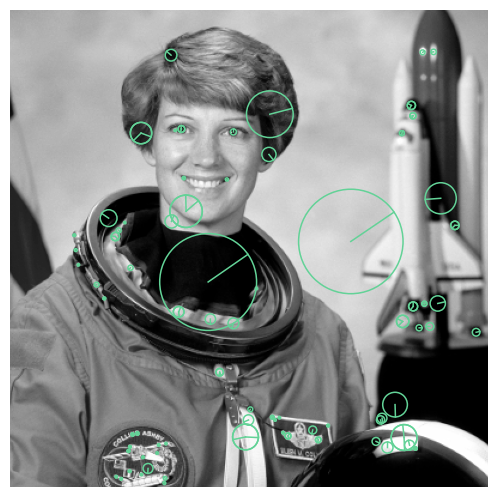

In [27]:
f = gris8(data.astronaut())[:400, 60:460]
kps = cv2.SIFT_create().detect(f, None)
grandes = sorted(kps, key=lambda k: -k.response)[:110]
fig, ax = plt.subplots(figsize=(6.2, 6.2))
ax.imshow(f)
dibujar_kps(ax, grandes)
ax.set_xlim(0, 399)
ax.set_ylim(399, 0)
limpiar(ax)
plt.show()

In [28]:
sift = cv2.SIFT_create()
kp, des = sift.detectAndCompute(gris8(data.astronaut()), None)
print(f"{len(kp)} puntos.  des.shape = {des.shape}, tipo {des.dtype}")
print(f"Primer punto: pt = {tuple(round(v, 1) for v in kp[0].pt)}, size = {kp[0].size:.1f}, "
      f"angle = {kp[0].angle:.0f}, response = {kp[0].response:.4f}")

1100 puntos.  des.shape = (1100, 128), tipo float32
Primer punto: pt = (4.7, 301.6), size = 3.4, angle = 140, response = 0.0237


### 4.5 Explora SIFT

Baja `contrastThreshold` y sube `edgeThreshold`. ¿Dónde aparecen los puntos nuevos? ¿Son buenos?

In [29]:
@interact(imagen=widgets.Dropdown(options=opciones_imagenes(), value="astronaut"),
          contraste=widgets.FloatLogSlider(value=0.04, base=10, min=-3, max=-0.7, step=0.1, description="contraste", continuous_update=False),
          bordes=widgets.FloatLogSlider(value=10, base=10, min=0, max=3, step=0.25, description="bordes", continuous_update=False),
          capas=widgets.IntSlider(value=3, min=1, max=6, description="capas/octava", continuous_update=False),
          mostrar=widgets.IntSlider(value=100, min=20, max=500, step=20, description="mostrar", continuous_update=False))
def explorar_sift(imagen, contraste, bordes, capas, mostrar):
    f = cargar(imagen)
    kps = cv2.SIFT_create(contrastThreshold=contraste, edgeThreshold=bordes, nOctaveLayers=capas).detect(f, None)
    mejores = sorted(kps, key=lambda v: -v.response)[:mostrar]
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(f)
    dibujar_kps(ax, mejores)
    ax.set_xlim(0, f.shape[1] - 1)
    ax.set_ylim(f.shape[0] - 1, 0)
    ax.set_title(f"{len(kps)} puntos en total; se muestran {len(mejores)}")
    limpiar(ax)
    plt.show()

interactive(children=(Dropdown(description='imagen', options=('astronaut', 'camera', 'coffee', 'chelsea', 'coi…

---
## 5. FAST, BRIEF y ORB

SIFT es robusto, pero caro. ¿Qué pasa si hay que procesar video en un teléfono?

### 5.1 FAST: una prueba sobre un anillo

En un anillo de 16 píxeles alrededor de $p$: ¿hay **$N$ contiguos** todos más claros que $I_p + t$, o todos más
oscuros que $I_p - t$? Suele usarse $N = 9$. En la figura, los píxeles verdes cumplen la condición.

No usa gradientes: **solo compara intensidades**.

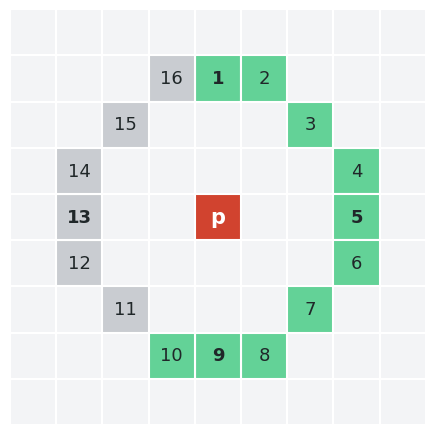

In [30]:
ANILLO = [(0, -3), (1, -3), (2, -2), (3, -1), (3, 0), (3, 1), (2, 2), (1, 3),
          (0, 3), (-1, 3), (-2, 2), (-3, 1), (-3, 0), (-3, -1), (-2, -2), (-1, -3)]

fig, ax = plt.subplots(figsize=(5.4, 5.4))
# los píxeles 1 a 10 son más claros que Ip + t; los demás, parecidos al centro
for y in range(-4, 5):
    for x in range(-4, 5):
        ax.add_patch(Rectangle((x - 0.5, y - 0.5), 1, 1, fc="#f3f4f6", ec="white", lw=1.5))
for i, (x, y) in enumerate(ANILLO, 1):
    claro = i <= 10
    ax.add_patch(Rectangle((x - 0.5, y - 0.5), 1, 1, fc=VERDE_CLARO if claro else "#c9ccd1", ec="white", lw=1.5))
    peso = "bold" if i in (1, 5, 9, 13) else "normal"
    ax.text(x, y, str(i), ha="center", va="center", fontsize=13, fontweight=peso, color="#202729")
ax.add_patch(Rectangle((-0.5, -0.5), 1, 1, fc=ROJO, ec="white", lw=1.5))
ax.text(0, 0, "p", ha="center", va="center", color="white", fontweight="bold", fontsize=15)
ax.set_xlim(-4.5, 4.5)
ax.set_ylim(4.5, -4.5)
ax.set_aspect("equal")
limpiar(ax)
plt.show()

Programemos la prueba. **Cuidado:** el anillo es circular, así que el píxel 16 y el 1 son vecinos.

In [31]:
def contiguos_circular(cumple):
    # Mayor racha de verdaderos, dando la vuelta al anillo
    n = len(cumple)
    if all(cumple):
        return n
    mejor = racha = 0
    for valor in list(cumple) * 2:
        racha = racha + 1 if valor else 0
        mejor = max(mejor, racha)
    return mejor


def es_esquina_fast(Ip, anillo, t=20, N=9):
    anillo = np.asarray(anillo, float)
    return (contiguos_circular(anillo > Ip + t) >= N) or (contiguos_circular(anillo < Ip - t) >= N)


def fast_manual(f, t=20, N=9):
    # Recorre la imagen píxel a píxel: lento, pero muestra el algoritmo
    f = f.astype(float)
    h, w = f.shape
    salida = np.zeros(f.shape, bool)
    dx, dy = np.array(ANILLO).T
    for y in range(3, h - 3):
        for x in range(3, w - 3):
            anillo = f[y + dy, x + dx]
            # Prueba rápida: si no hay al menos 2 de 4 compatibles, N = 9 no es posible
            brujula = f[[y - 3, y, y + 3, y], [x, x + 3, x, x - 3]]
            if (brujula > f[y, x] + t).sum() < 2 and (brujula < f[y, x] - t).sum() < 2:
                continue
            salida[y, x] = es_esquina_fast(f[y, x], anillo, t, N)
    return salida


recorte = gris8(data.camera())[60:220, 150:310]
inicio = time.perf_counter()
mano = fast_manual(recorte, t=25)
t_mano = time.perf_counter() - inicio

detector_cv = cv2.FastFeatureDetector_create(threshold=25, nonmaxSuppression=False)
inicio = time.perf_counter()
puntos = detector_cv.detect(recorte, None)
t_cv = time.perf_counter() - inicio
ocv = np.zeros(recorte.shape, bool)
for kp in puntos:
    ocv[int(kp.pt[1]), int(kp.pt[0])] = True
print(f"A mano:  {mano.sum()} puntos en {1000 * t_mano:8.1f} ms")
print(f"OpenCV:  {ocv.sum()} puntos en {1000 * t_cv:8.1f} ms")
print(f"Coinciden: {(mano & ocv).sum()} puntos")

A mano:  874 puntos en    102.3 ms
OpenCV:  874 puntos en      0.3 ms
Coinciden: 874 puntos


### 5.2 Umbral y supresión

Como la prueba es binaria, FAST marca grupos de píxeles vecinos. La supresión de no máximos deja uno por grupo.

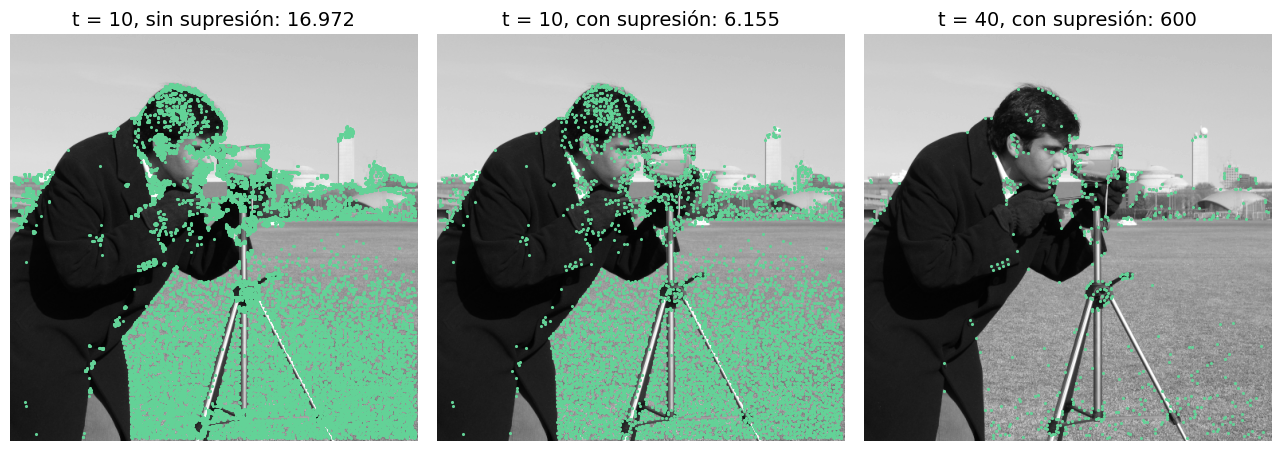

In [32]:
f = gris8(data.camera())
fig, ax = plt.subplots(1, 3, figsize=(13, 4.6))
conf = [(10, False), (10, True), (40, True)]
for a, (t, nms) in zip(ax, conf):
    kps = cv2.FastFeatureDetector_create(threshold=t, nonmaxSuppression=nms).detect(f, None)
    a.imshow(f)
    a.plot([k.pt[0] for k in kps], [k.pt[1] for k in kps], ".", color=VERDE_CLARO, ms=2.5)
    a.set_title(f"t = {t}, {'con' if nms else 'sin'} supresión: " + f"{len(kps):,}".replace(",", "."))
limpiar(ax)
fig.tight_layout()
plt.show()

### 5.3 BRIEF: un descriptor de bits

Se comparan pares de píxeles fijos en un parche suavizado, y cada comparación da **un bit**:

$$\tau(p, q) = \begin{cases} 1 & I(p) < I(q) \\ 0 & \text{en otro caso} \end{cases}$$

Se comparan con **distancia de Hamming**, que cuenta los bits distintos.

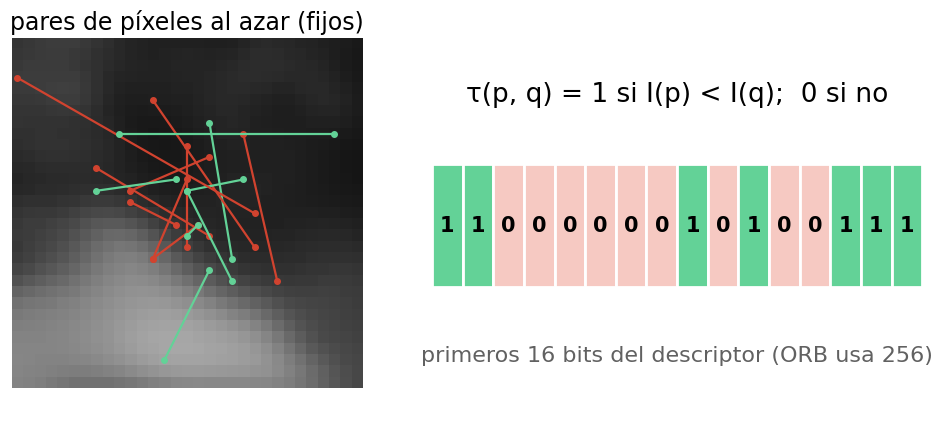

In [33]:
rng = np.random.default_rng(1)
f = gris(data.camera())
y, x, L = 110, 220, 31
par = ndimage.gaussian_filter(f, 1.5)[y: y + L, x: x + L]
n = 16
p = np.clip(rng.normal(L / 2, L / 5, (n, 2)), 0, L - 1).astype(int)
q = np.clip(rng.normal(L / 2, L / 5, (n, 2)), 0, L - 1).astype(int)
bits = [int(par[a[1], a[0]] < par[b[1], b[0]]) for a, b in zip(p, q)]
fig, ax = plt.subplots(1, 2, figsize=(10, 4.4), gridspec_kw=dict(width_ratios=[1, 1.4]))
ax[0].imshow(par, vmin=0, vmax=1)
for a, b, v in zip(p, q, bits):
    ax[0].plot([a[0], b[0]], [a[1], b[1]], "-o", color=VERDE_CLARO if v else ROJO, lw=1.6, ms=4)
ax[0].set_title("pares de píxeles al azar (fijos)", fontsize=17)
ax[1].set_xlim(0, n)
ax[1].set_ylim(-1, 2.2)
for i, v in enumerate(bits):
    ax[1].add_patch(Rectangle((i, 0), 1, 1, fc=VERDE_CLARO if v else "#f6c9c2", ec="white", lw=2))
    ax[1].text(i + 0.5, 0.5, str(v), ha="center", va="center", fontsize=15, fontweight="bold")
ax[1].text(n / 2, 1.5, "τ(p, q) = 1 si I(p) < I(q);  0 si no", ha="center", fontsize=19)
ax[1].text(n / 2, -0.6, f"primeros {n} bits del descriptor (ORB usa 256)", ha="center", color=GRIS, fontsize=16)
limpiar(ax)
fig.tight_layout()
plt.show()

¿Cuánto se gana con Hamming? Comparemos la memoria y el tiempo de buscar el vecino más cercano, con descriptores reales.

In [34]:
f = gris8(data.astronaut())
_, d_sift = cv2.SIFT_create(nfeatures=1000).detectAndCompute(f, None)
_, d_orb = cv2.ORB_create(nfeatures=1000).detectAndCompute(f, None)
print(f"SIFT: {d_sift.shape[1]} valores {d_sift.dtype} = {d_sift[0].nbytes} bytes por descriptor")
print(f"ORB:  {d_orb.shape[1]} valores {d_orb.dtype} = {d_orb[0].nbytes} bytes por descriptor")

rng = np.random.default_rng(0)
for nombre, d, norma in [("SIFT, L2", d_sift, cv2.NORM_L2), ("ORB, Hamming", d_orb, cv2.NORM_HAMMING)]:
    m = cv2.BFMatcher(norma)
    otra = d[rng.permutation(len(d))]
    tiempos = []
    for _ in range(30):
        inicio = time.perf_counter()
        m.match(d, otra)
        tiempos.append(time.perf_counter() - inicio)
    print(f"{nombre:13s} {1000 * np.median(tiempos):7.2f} ms por búsqueda ({len(d)} descriptores)")

SIFT: 128 valores float32 = 512 bytes por descriptor
ORB:  32 valores uint8 = 32 bytes por descriptor
SIFT, L2         0.64 ms por búsqueda (1000 descriptores)
ORB, Hamming     0.40 ms por búsqueda (1000 descriptores)


ORB usa 16 veces menos memoria por descriptor. En tiempo también gana, aunque menos de lo que se suele esperar: OpenCV ya
acelera L2 con instrucciones vectoriales.

### 5.4 ORB: orientar con el centroide

ORB calcula el centroide de intensidad de un parche circular, con los momentos $m_{pq} = \sum x^p y^q I(x, y)$. La
orientación es la dirección del centro al centroide:

$$\theta = \operatorname{atan2}(m_{01}, m_{10})$$

Aquí el mismo parche se giró 60°, y $\theta$ se mueve en esa cantidad.

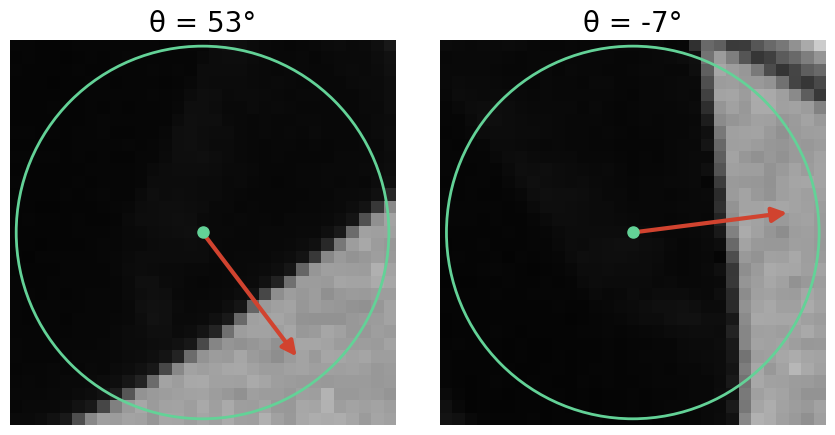

In [35]:
f = gris(data.camera())
fig, ax = plt.subplots(1, 2, figsize=(8.8, 4.4))
M = cv2.getRotationMatrix2D((256.0, 256.0), 60, 1.0)
g = cv2.warpAffine(f, M, (512, 512), flags=cv2.INTER_CUBIC)
x, y = 272, 290
xr, yr = M @ np.array([x, y, 1.0])
R = 15
angs = []
for a, im, cx, cy in [(ax[0], f, x, y), (ax[1], g, int(round(xr)), int(round(yr)))]:
    par = im[cy - R: cy + R + 1, cx - R: cx + R + 1]
    yy, xx = np.mgrid[-R: R + 1, -R: R + 1]
    m = xx**2 + yy**2 <= R**2
    m00, m10, m01 = par[m].sum(), (xx * par)[m].sum(), (yy * par)[m].sum()
    cxx, cyy = m10 / m00, m01 / m00
    t = np.rad2deg(np.arctan2(m01, m10))
    angs.append(t)
    a.imshow(par, vmin=0, vmax=1)
    a.add_patch(Circle((R, R), R, fill=False, color=VERDE_CLARO, lw=2))
    esc = R * 0.85 / np.hypot(cxx, cyy)
    a.add_patch(FancyArrowPatch((R, R), (R + cxx * esc, R + cyy * esc), arrowstyle="-|>", mutation_scale=22, color=ROJO, lw=3))
    a.plot(R, R, "o", color=VERDE_CLARO, ms=8)
    a.set_title(f"θ = {t:.0f}°", fontsize=20)
limpiar(ax)
fig.tight_layout()
plt.show()

### 5.5 ORB en OpenCV

**ORB = FAST orientado + BRIEF rotado:**

- **Pirámide** de imágenes, para la escala.
- **Medida de Harris**, para quedarse con los mejores puntos de FAST.
- **Centroide**, para la orientación.
- **BRIEF con los pares rotados** según $\theta$, en 256 bits.

500 puntos.  des.shape = (500, 32), tipo uint8


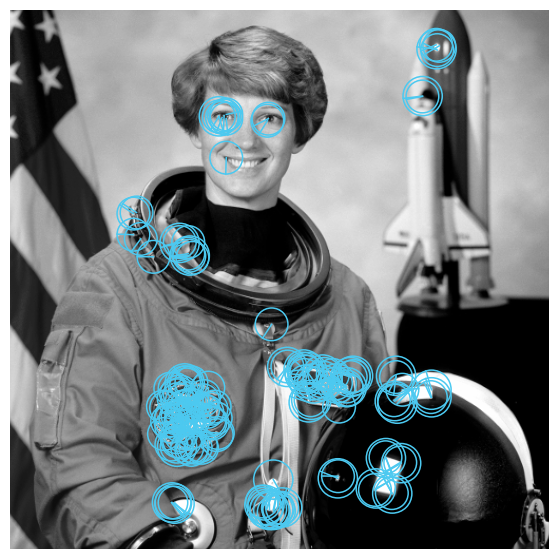

In [36]:
orb = cv2.ORB_create(nfeatures=500)
kp, des = orb.detectAndCompute(gris8(data.astronaut()), None)
print(f"{len(kp)} puntos.  des.shape = {des.shape}, tipo {des.dtype}")

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(gris8(data.astronaut()))
dibujar_kps(ax, kp[:150], col="#4cc9f0")
ax.set_xlim(0, 511)
ax.set_ylim(511, 0)
limpiar(ax)
plt.show()

---
## 6. Comparación de los métodos

### 6.1 Cuatro detectores, una imagen

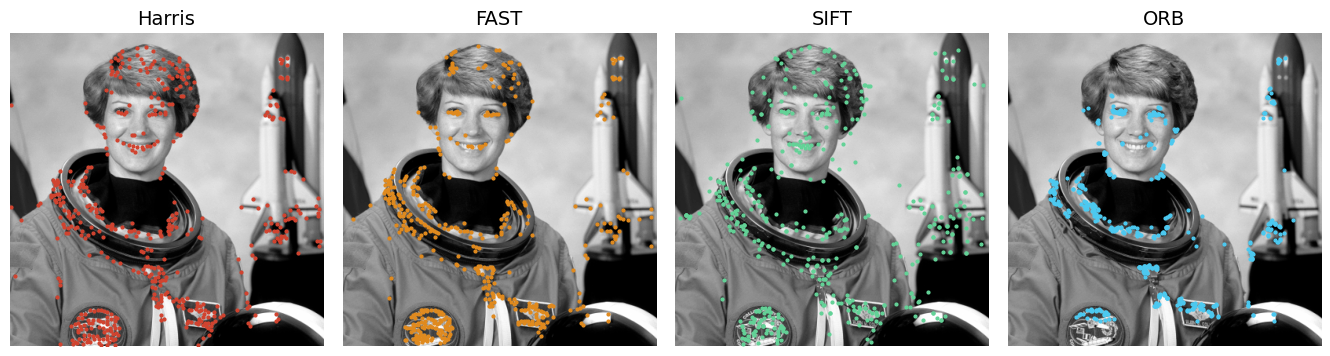

In [37]:
def detector(nombre, n=500):
    if nombre == "Harris":
        def det(im):
            p = cv2.goodFeaturesToTrack(im, n, 0.001, 3, useHarrisDetector=True, k=0.05)
            return np.zeros((0, 2)) if p is None else p.reshape(-1, 2)
        return det
    if nombre == "FAST":
        d = cv2.FastFeatureDetector_create(threshold=15)
    elif nombre == "SIFT":
        d = cv2.SIFT_create(nfeatures=n)
    else:
        d = cv2.ORB_create(nfeatures=n)

    def det(im):
        k = sorted(d.detect(im, None), key=lambda v: -v.response)[:n]
        return np.array([v.pt for v in k]).reshape(-1, 2)
    return det


f = gris8(data.astronaut())[:400, 60:460]
fig, ax = plt.subplots(1, 4, figsize=(13.5, 3.8))
for a, n, c in zip(ax, ["Harris", "FAST", "SIFT", "ORB"], [ROJO, NARANJA, VERDE_CLARO, "#4cc9f0"]):
    p = detector(n, 500)(f)
    a.imshow(f)
    a.plot(p[:, 0], p[:, 1], ".", color=c, ms=4)
    a.set_title(n)
limpiar(ax)
fig.tight_layout()
plt.show()

### 6.2 ¿Se vuelve a detectar el mismo punto?

Se transforma la imagen, se detecta en ambas y se cuenta cuántos puntos coinciden **en posición**, uno a uno.
La curva punteada es lo que se obtiene con puntos al azar.

In [38]:
def repetibilidad(det, im, A, forma, s=1.0, tol=2.0, margen=15, g=None, azar=False):
    # A: matriz 2x3 de im a su transformada. Cuenta parejas uno a uno, con la distancia
    # medida en la imagen más chica. Con azar=True reemplaza los puntos por puntos al azar.
    B = g if g is not None else cv2.warpAffine(im, A, forma[::-1], flags=cv2.INTER_LINEAR)
    pa, pb = det(im), det(B)
    if azar:
        rng = np.random.default_rng(0)
        pa = rng.uniform(0, 1, pa.shape) * [im.shape[1], im.shape[0]]
        pb = rng.uniform(0, 1, pb.shape) * [forma[1], forma[0]]
    Ah = np.vstack([A, [0, 0, 1]])
    Ai = np.linalg.inv(Ah)

    def dentro(p, h, w):
        return (p[:, 0] > margen) & (p[:, 0] < w - margen) & (p[:, 1] > margen) & (p[:, 1] < h - margen)
    pa_b = pa @ Ah[:2, :2].T + Ah[:2, 2]
    pb_a = pb @ Ai[:2, :2].T + Ai[:2, 2]
    pa_b = pa_b[dentro(pa_b, *forma) & dentro(pa, *im.shape)]
    pb = pb[dentro(pb_a, *im.shape) & dentro(pb, *forma)]
    if len(pa_b) < 5 or len(pb) < 5:
        return np.nan
    d = np.hypot(*(pa_b[:, None] - pb[None]).transpose(2, 0, 1)) / max(s, 1.0)
    usados_a, usados_b, n = set(), set(), 0
    for i, j in zip(*np.unravel_index(np.argsort(d, axis=None), d.shape)):
        if d[i, j] > tol:
            break
        if i not in usados_a and j not in usados_b:
            usados_a.add(i)
            usados_b.add(j)
            n += 1
    return 100 * n / min(len(pa_b), len(pb))

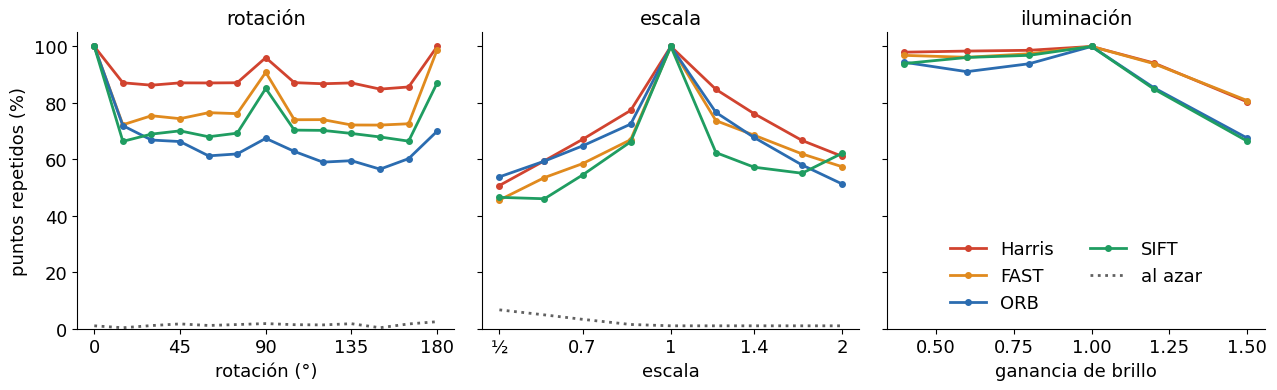

In [39]:
imgs = [gris8(i) for i in (data.astronaut(), data.camera(), data.coffee(), data.chelsea())]
nombres = ["Harris", "FAST", "ORB", "SIFT"]
cols = {"Harris": ROJO, "FAST": NARANJA, "ORB": AZUL, "SIFT": VERDE}
giros = list(range(0, 181, 15))
escalas = [0.5, 0.6, 0.7, 0.85, 1.0, 1.2, 1.4, 1.7, 2.0]
ganancias = [0.4, 0.6, 0.8, 1.0, 1.2, 1.5]
n_puntos = 200

def escala(det, im, s, azar=False):
    h, w = im.shape
    A = np.array([[s, 0, 0], [0, s, 0]], float)
    forma = (int(h * s), int(w * s))
    g = cv2.resize(im, forma[::-1], interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_LINEAR)
    return repetibilidad(det, im, A, forma, s=s, g=g, azar=azar)

def giro(det, im, t, azar=False):
    h, w = im.shape
    return repetibilidad(det, im, cv2.getRotationMatrix2D((w / 2, h / 2), t, 1.0), im.shape, azar=azar)

res = {}
for n in nombres:
    det = detector(n, n_puntos)
    res[n] = dict(
        r=[np.nanmean([giro(det, im, t) for im in imgs]) for t in giros],
        s=[np.nanmean([escala(det, im, e) for im in imgs]) for e in escalas],
        g=[np.nanmean([repetibilidad(det, im, np.array([[1, 0, 0], [0, 1, 0]], float), im.shape,
                                     g=np.clip(im.astype(float) * c, 0, 255).astype(np.uint8)) for im in imgs])
           for c in ganancias])
det = detector("SIFT", n_puntos)
azar_s = [np.nanmean([escala(det, im, e, azar=True) for im in imgs]) for e in escalas]
azar_r = [np.nanmean([giro(det, im, t, azar=True) for im in imgs]) for t in giros]
fig, ax = plt.subplots(1, 3, figsize=(13, 4.1), sharey=True)
for n in nombres:
    ax[0].plot(giros, res[n]["r"], "-o", ms=4, lw=2, color=cols[n], label=n)
    ax[1].plot(escalas, res[n]["s"], "-o", ms=4, lw=2, color=cols[n], label=n)
    ax[2].plot(ganancias, res[n]["g"], "-o", ms=4, lw=2, color=cols[n], label=n)
ax[0].plot(giros, azar_r, ":", color=GRIS, lw=2, label="al azar")
ax[1].plot(escalas, azar_s, ":", color=GRIS, lw=2, label="al azar")
ax[0].set_xlabel("rotación (°)")
ax[0].set_xticks(range(0, 181, 45))
ax[1].set_xlabel("escala")
ax[1].set_xscale("log")
ax[1].set_xticks([0.5, 0.7, 1, 1.4, 2])
ax[1].set_xticklabels(["½", "0.7", "1", "1.4", "2"])
ax[1].minorticks_off()
ax[2].set_xlabel("ganancia de brillo")
ax[0].set_ylabel("puntos repetidos (%)")
ax[0].set_ylim(0, 105)
ax[2].legend(*ax[0].get_legend_handles_labels(), frameon=False, ncol=2, loc="lower center")
for a, t in zip(ax, ["rotación", "escala", "iluminación"]):
    a.set_title(t)
fig.tight_layout()
plt.show()

Resultado que vale la pena comentar: **solo por posición**, Harris compite bien, incluso en escala. Las imágenes reales
tienen esquinas nítidas en muchos tamaños, y aquí el rango va solo de ½ a 2.

Pero esto solo mide **dónde**. No dice si después se puede reconocer el punto.

### 6.3 ¿Se reconoce el punto?

Ahora se detecta y se describe en ambas imágenes, y se cuenta cuántos puntos encuentran a su pareja correcta, usando solo
el vecino más cercano. "Harris + parche" significa: esquina de Harris, descrita con un parche de 21 × 21 píxeles sin
escala ni orientación.

In [40]:
def describir(nombre, im, n=300):
    # Devuelve puntos, descriptores y la norma con que se comparan
    if nombre == "SIFT":
        k, d = cv2.SIFT_create(nfeatures=n).detectAndCompute(im, None)
        return np.array([v.pt for v in k]), d, cv2.NORM_L2
    if nombre == "ORB":
        k, d = cv2.ORB_create(nfeatures=n).detectAndCompute(im, None)
        return np.array([v.pt for v in k]), d, cv2.NORM_HAMMING
    # Harris + parche de 21 x 21 sin orientación ni escala, normalizado
    p = cv2.goodFeaturesToTrack(im, n, 0.001, 3, useHarrisDetector=True, k=0.05).reshape(-1, 2)
    r = 10
    h, w = im.shape
    p = p[(p[:, 0] > r) & (p[:, 0] < w - r - 1) & (p[:, 1] > r) & (p[:, 1] < h - r - 1)]
    d = []
    for x, y in p.astype(int):
        v = im[y - r: y + r + 1, x - r: x + r + 1].astype(np.float32).ravel()
        d.append((v - v.mean()) / (v.std() + 1e-6))
    return p, np.array(d, np.float32), cv2.NORM_L2


def pares_correctos(nombre, im, g, A, s, tol=3.0, margen=15):
    pa, da, norma = describir(nombre, im)
    pb, db, _ = describir(nombre, g)
    Ah = np.vstack([A, [0, 0, 1]])
    pa_b = pa @ Ah[:2, :2].T + Ah[:2, 2]
    h, w = g.shape
    visible = (pa_b[:, 0] > margen) & (pa_b[:, 0] < w - margen) & (pa_b[:, 1] > margen) & (pa_b[:, 1] < h - margen)
    pa_b, da = pa_b[visible], da[visible]
    if len(pa_b) < 5:
        return np.nan
    m = cv2.BFMatcher(norma).match(da, db)
    bien = sum(np.hypot(*(pa_b[v.queryIdx] - pb[v.trainIdx])) / max(s, 1.0) <= tol for v in m)
    return 100 * bien / len(pa_b)

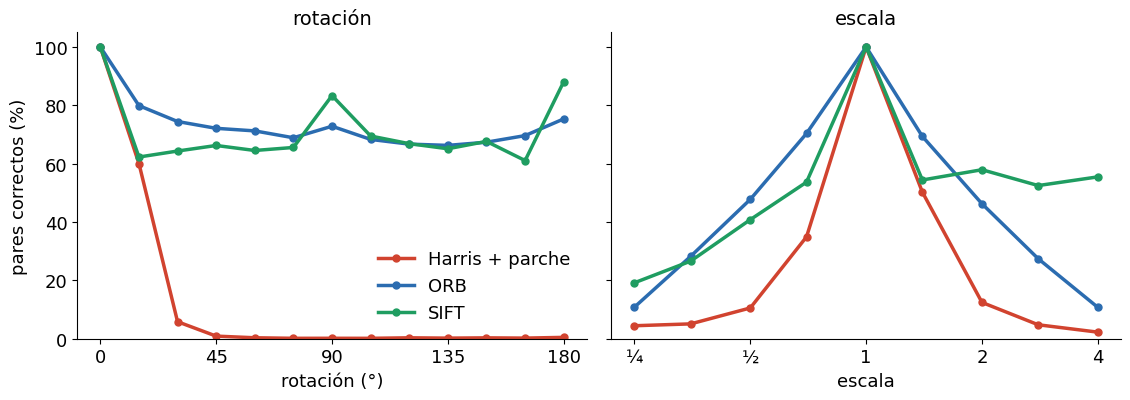

In [41]:
imgs = [gris8(i) for i in (data.astronaut(), data.camera(), data.coffee(), data.chelsea())]
nombres = ["Harris + parche", "ORB", "SIFT"]
cols = {"Harris + parche": ROJO, "ORB": AZUL, "SIFT": VERDE}
giros = list(range(0, 181, 15))
escalas = [0.25, 0.35, 0.5, 0.7, 1.0, 1.4, 2.0, 2.8, 4.0]

def giro(n, im, t):
    h, w = im.shape
    A = cv2.getRotationMatrix2D((w / 2, h / 2), t, 1.0)
    return pares_correctos(n.split()[0], im, cv2.warpAffine(im, A, (w, h), flags=cv2.INTER_LINEAR), A, 1.0)

def escala(n, im, e):
    h, w = im.shape
    A = np.array([[e, 0, 0], [0, e, 0]], float)
    g = cv2.resize(im, (int(w * e), int(h * e)), interpolation=cv2.INTER_AREA if e < 1 else cv2.INTER_LINEAR)
    return pares_correctos(n.split()[0], im, g, A, e)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
for n in nombres:
    r = [np.nanmean([giro(n, im, t) for im in imgs]) for t in giros]
    e = [np.nanmean([escala(n, im, v) for im in imgs]) for v in escalas]
    ax[0].plot(giros, r, "-o", ms=5, lw=2.5, color=cols[n], label=n)
    ax[1].plot(escalas, e, "-o", ms=5, lw=2.5, color=cols[n], label=n)
ax[0].set_xlabel("rotación (°)")
ax[0].set_xticks(range(0, 181, 45))
ax[0].set_ylabel("pares correctos (%)")
ax[0].set_ylim(0, 105)
ax[0].legend(frameon=False)
ax[1].set_xlabel("escala")
ax[1].set_xscale("log")
ax[1].set_xticks([0.25, 0.5, 1, 2, 4])
ax[1].set_xticklabels(["¼", "½", "1", "2", "4"])
ax[1].minorticks_off()
ax[0].set_title("rotación")
ax[1].set_title("escala")
fig.tight_layout()
plt.show()

- El **parche fijo** colapsa al rotar.
- **SIFT y ORB** resisten la rotación.
- Al **ampliar**, SIFT se mantiene mejor.
- Al **reducir mucho**, caen todos: esos detalles ya no existen en la imagen.

Detectar no es lo mismo que reconocer. **Eso es lo que aporta el descriptor.**

Estos porcentajes son sin ningún filtro de pares. La prueba de razón y RANSAC, las próximas clases, limpian el resultado.

### 6.4 ¿Cuánto cuestan?

Los valores cambian según el computador y el número de puntos. Lo importante es el orden de magnitud.

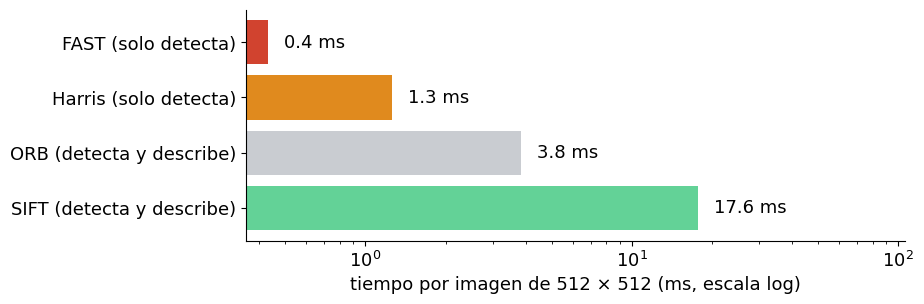

In [42]:
f = gris8(data.astronaut())
def medir(fn, r=30):
    fn()
    t = time.perf_counter()
    for _ in range(r):
        out = fn()
    return 1000 * (time.perf_counter() - t) / r, out
sift, orb = cv2.SIFT_create(nfeatures=2000), cv2.ORB_create(nfeatures=2000)
fast = cv2.FastFeatureDetector_create(threshold=15)
filas = [("FAST (solo detecta)", lambda: fast.detect(f, None)),
         ("Harris (solo detecta)", lambda: cv2.cornerHarris(np.float32(f), 3, 3, 0.05)),
         ("ORB (detecta y describe)", lambda: orb.detectAndCompute(f, None)),
         ("SIFT (detecta y describe)", lambda: sift.detectAndCompute(f, None))]
tiempos = [medir(fn)[0] for _, fn in filas]
fig, ax = plt.subplots(figsize=(8.5, 3.0))
b = ax.barh([n for n, _ in filas][::-1], tiempos[::-1], color=[ROJO, NARANJA, "#c9ccd1", VERDE_CLARO][::-1])
ax.set_xscale("log")
for r, t in zip(b, tiempos[::-1]):
    ax.text(t * 1.15, r.get_y() + r.get_height() / 2, f"{t:.1f} ms", va="center")
ax.set_xlim(right=max(tiempos) * 6)
ax.set_xlabel("tiempo por imagen de 512 × 512 (ms, escala log)")
plt.show()

### 6.5 Explora: tu propia transformación

Elige una imagen, una rotación y una escala. Los pares verdes son correctos y los rojos, incorrectos.

In [43]:
@interact(imagen=widgets.Dropdown(options=opciones_imagenes(), value="astronaut"),
          metodo=widgets.ToggleButtons(options=["SIFT", "ORB", "Harris + parche"], description="método"),
          giro=widgets.IntSlider(value=30, min=0, max=180, step=5, description="rotación", continuous_update=False),
          escala=widgets.FloatLogSlider(value=1.0, base=2, min=-2, max=2, step=0.25, description="escala", continuous_update=False),
          n=widgets.IntSlider(value=40, min=10, max=150, step=10, description="dibujar", continuous_update=False))
def explorar_pares(imagen, metodo, giro, escala, n):
    f = cargar(imagen)
    h, w = f.shape
    # Lienzo suficiente para que la imagen rotada y escalada quepa completa
    c, s = abs(np.cos(np.deg2rad(giro))) * escala, abs(np.sin(np.deg2rad(giro))) * escala
    W, H = int(w * c + h * s) + 1, int(w * s + h * c) + 1
    A = cv2.getRotationMatrix2D((w / 2, h / 2), giro, escala)
    A[:, 2] += [W / 2 - w / 2, H / 2 - h / 2]
    g = cv2.warpAffine(f, A, (W, H), flags=cv2.INTER_AREA if escala < 1 else cv2.INTER_LINEAR)

    pa, da, norma = describir(metodo.split()[0], f)
    pb, db, _ = describir(metodo.split()[0], g)
    pares = cv2.BFMatcher(norma).match(da, db)
    real = pa @ A[:2, :2].T + A[:2, 2]
    ok = [np.hypot(*(real[m.queryIdx] - pb[m.trainIdx])) / max(escala, 1) <= 3 for m in pares]
    # Se dibuja una muestra pareja, no solo los mejores
    orden = np.linspace(0, len(pares) - 1, min(n, len(pares))).astype(int)

    alto = max(h, H)
    lienzo = np.full((alto, w + 20 + W), 255, np.uint8)
    lienzo[:h, :w] = f
    lienzo[:H, w + 20:] = g
    fig, ax = plt.subplots(figsize=(13, 6))
    ax.imshow(lienzo, vmin=0, vmax=255)
    for i in orden:
        xa, ya = pa[pares[i].queryIdx]
        xb, yb = pb[pares[i].trainIdx]
        ax.plot([xa, xb + w + 20], [ya, yb], color=VERDE_CLARO if ok[i] else ROJO, lw=1)
    ax.set_title(f"{metodo}: {100 * np.mean(ok):.0f} % de pares correctos ({sum(ok)} de {len(ok)})")
    limpiar(ax)
    plt.show()

interactive(children=(Dropdown(description='imagen', options=('astronaut', 'camera', 'coffee', 'chelsea', 'coi…

### 6.6 Resumen: ¿qué uso?

| Necesidad | Método |
|---|---|
| Solo esquinas, sin grandes cambios de escala | Harris o Shi-Tomasi: `cv2.goodFeaturesToTrack` |
| Máxima velocidad de detección | FAST, sin descriptor propio |
| Tiempo real o poca memoria | ORB: descriptor binario, distancia de Hamming |
| Máxima robustez, cambios de escala | SIFT: 128 valores, distancia L2 |

---
## 7. Ejercicios a mano: comprueba tus cálculos

Son los ejercicios de las láminas. **Primero resuélvelos con lápiz y papel**, y usa estas celdas para comprobar.

### Ejercicio 1: la matriz $M$

Para la imagen de 5 × 5, considera la ventana de los 9 píxeles centrales con $w = 1$. Usa
$I_x = I(x + 1, y) - I(x - 1, y)$ e $I_y = I(x, y + 1) - I(x, y - 1)$.

In [44]:
I = np.array([[0, 0, 0, 0, 0],
              [0, 0, 0, 0, 0],
              [0, 0, 4, 4, 4],
              [0, 0, 4, 4, 4],
              [0, 0, 4, 4, 4]], float)   # prueba con un borde: todas las filas iguales a [0, 0, 4, 4, 4]
k = 0.05

Ix = I[1:4, 2:5] - I[1:4, 0:3]
Iy = I[2:5, 1:4] - I[0:3, 1:4]
M = np.array([[(Ix * Ix).sum(), (Ix * Iy).sum()],
              [(Ix * Iy).sum(), (Iy * Iy).sum()]])
print("Ix =\n", Ix, "\nIy =\n", Iy, "\nM =\n", M)
print("λ =", np.linalg.eigvalsh(M)[::-1], "  det =", np.linalg.det(M).round(4), "  tr =", np.trace(M))
print("R =", (np.linalg.det(M) - k * np.trace(M) ** 2).round(4))

Ix =
 [[0. 0. 0.]
 [4. 4. 0.]
 [4. 4. 0.]] 
Iy =
 [[0. 4. 4.]
 [0. 4. 4.]
 [0. 0. 0.]] 
M =
 [[64. 16.]
 [16. 64.]]
λ = [80. 48.]   det = 3840.0   tr = 128.0
R = 3020.8


### Ejercicio 2: clasificar

Con $k = 0.05$, calcula $R$ y clasifica. ¿Qué ocurre con $R$ si la imagen se multiplica por 2?

In [45]:
k = 0.05
casos = {"M_A": [[2, 0], [0, 1]], "M_B": [[500, 0], [0, 3]], "M_C": [[400, 100], [100, 300]]}
for nombre, M in casos.items():
    M = np.array(M, float)
    R = np.linalg.det(M) - k * np.trace(M) ** 2
    print(f"{nombre}: λ = {np.round(np.linalg.eigvalsh(M)[::-1], 1)}   det = {np.linalg.det(M):9.1f}   "
          f"tr = {np.trace(M):6.1f}   R = {R:10.2f}")

# Imagen × 2: los gradientes × 2, y M × 4
M = np.array(casos["M_C"], float)
R1 = np.linalg.det(M) - k * np.trace(M) ** 2
R2 = np.linalg.det(4 * M) - k * np.trace(4 * M) ** 2
print(f"\nCon la imagen × 2, R se multiplica por {R2 / R1:.0f}")

M_A: λ = [2. 1.]   det =       2.0   tr =    3.0   R =       1.55
M_B: λ = [500.   3.]   det =    1500.0   tr =  503.0   R =  -11150.45
M_C: λ = [461.8 238.2]   det =  110000.0   tr =  700.0   R =   85500.00

Con la imagen × 2, R se multiplica por 16


### Ejercicio 3: orientación y descriptor

Con un histograma de **8 bins** de 45°, calcula la orientación de estos gradientes. ¿Cuántos puntos se crean, con la
regla del 80 %? (Versión simplificada, sin peso gaussiano.)

In [46]:
gradientes = [(2, 10), (4, 20), (3, 40), (5, 35), (1, 100), (7, 190), (5, 215), (2, 300)]   # (magnitud, ángulo)

hist = np.zeros(8)
for magnitud, angulo in gradientes:
    hist[angulo // 45] += magnitud
print("Histograma:", hist)
print("Puntos creados, con el centro del bin como orientación:",
      [f"{45 * i + 22.5}°" for i in np.nonzero(hist >= 0.8 * hist.max())[0]])
print("Segundo bin / peak:", np.round(np.sort(hist)[-2] / hist.max(), 3))

print("\nTamaño con 3 x 3 celdas y 6 ángulos:", 3 * 3 * 6)
for v in ([3.0, 4.0], [6.0, 8.0]):
    print(v, "normalizado:", np.array(v) / np.linalg.norm(v))

Histograma: [14.  0.  1.  0. 12.  0.  2.  0.]
Puntos creados, con el centro del bin como orientación: ['22.5°', '202.5°']
Segundo bin / peak: 0.857

Tamaño con 3 x 3 celdas y 6 ángulos: 54
[3.0, 4.0] normalizado: [0.6 0.8]
[6.0, 8.0] normalizado: [0.6 0.8]


### Ejercicio 4: FAST y Hamming

Con $I_p = 100$, $t = 20$ y $N = 9$: ¿son esquinas los anillos A y B? ¿Qué descriptor es el más cercano a $a$?

In [47]:
anillo_A = [130, 135, 128, 140, 125, 132, 126, 138, 129, 124, 95, 90, 101, 98, 105, 110]
anillo_B = [125, 130, 135, 128, 122, 100, 100, 99, 101, 98, 100, 102, 123, 124, 127, 129]
for nombre, anillo in (("A", anillo_A), ("B", anillo_B)):
    claros = np.array(anillo) > 120
    print(f"Anillo {nombre}: {contiguos_circular(claros)} contiguos más claros → esquina: {es_esquina_fast(100, anillo)}")

brujula = np.array(anillo_A)[[0, 4, 8, 12]]
print(f"Prueba rápida del anillo A (posiciones 1, 5, 9, 13): {brujula}, cumplen {(brujula > 120).sum()} de 4")

a, b, c = 0b10110100, 0b10011110, 0b01001011
print(f"\nHamming(a, b) = {bin(a ^ b).count('1')}   Hamming(a, c) = {bin(a ^ c).count('1')}")

Anillo A: 10 contiguos más claros → esquina: True
Anillo B: 9 contiguos más claros → esquina: True
Prueba rápida del anillo A (posiciones 1, 5, 9, 13): [130 125 129 101], cumplen 3 de 4

Hamming(a, b) = 3   Hamming(a, c) = 8


---
## 8. Actividad final: comparar detectores

Esta actividad no es evaluada. Usa una imagen de `skimage.data` o una propia, y todas las funciones de este cuaderno.

**Parte 1: detectar**

Detecta puntos con Harris, FAST, SIFT y ORB. ¿Cuántos puntos encuentra cada uno? ¿Dónde están? ¿Quedan bien repartidos?

**Parte 2: transformar**

Aplica una rotación y un cambio de escala. Como conoces la transformación, calcula qué porcentaje de puntos se repite.

**Parte 3: reconocer**

Compara descriptores con el vecino más cercano y cuenta cuántos pares son correctos.

**Preguntas para discutir**

- ¿Qué método repite mejor la posición? ¿Es el mismo que reconoce mejor los puntos?
- ¿Qué ocurre con una textura repetitiva, como `brick`? ¿Por qué?
- ¿Qué método usarías para unir un panorama? ¿Y para seguir objetos en video en un teléfono?

In [48]:
# 1. Detectar con los cuatro métodos

In [49]:
# 2. Transformar y calcular la repetibilidad

In [50]:
# 3. Comparar descriptores y contar los pares correctos